# **4 Кейс**

**Описание кейса:** требуется классифицировать риск задержки доставки заказа более чем на 5 минут от обещанного времени на этапе оформления, используя параметры ресторана, рейтинг курьера, погодные условия и пробки.

https://www.kaggle.com/datasets/razanihababdellatif/food-delivery-orders-and-eta-logistics-dataset

## **Импорт библиотек**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## **Загрузка данных**

In [2]:
df = pd.read_csv("food_delivery_orders_dataset.csv")

## **Первичный анализ**

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,Healthy,4.4,4,64.82,0,9.07,2.40,0.00,76.29,Credit Card,11.36,1.1,Rain,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,Dessert,4.4,2,13.03,0,1.82,0.84,3.25,18.94,Cash,1.09,2.5,Cloudy,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,Dessert,4.8,1,10.12,10,1.28,0.56,7.90,18.85,Cash,0.00,11.8,Cloudy,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,18,New,Fast Food,Local,3.9,1,8.86,10,1.12,0.40,4.70,14.19,Digital Wallet,0.00,5.4,Cloudy,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,20,Regular,Casual Dining,Pizza,3.5,1,15.08,20,1.69,0.65,5.05,19.45,Credit Card,1.70,6.1,Rain,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


Целевой показатель - **late_delivery**  
Заказ помечается как доставленный с опозданием (late_delivery = 1.0) только в том случае, если фактическое время доставки превышает расчетное более чем на 5 минут

Явно лишние показатели:  
**order_id**, **customer_id**, **restaurant_id** и **driver_id** - сами по себе не несут смысла, возможно можно рассмотреть для расчета дополнительных показателей  
**actual_delivery_time_minutes** - фактическое время доставки не имеет значения, важен факт опоздал курьер или нет

Показатели **order_date**, **order_hour**, **day_of_week**, **is_weekend** можно выразить из **order_timestamp**  
Показатель **city** можно выразить из **delivery_area**.  
Показатель **order_total** выражается из суммы показателей (**subtotal** - **discount_percent**%), **tax_amount**, **service_fee**, **delivery_fee**

In [4]:
df['late_delivery'].value_counts()

late_delivery
0.0    31164
1.0    17968
Name: count, dtype: int64

Есть перевес в сторону записей без опоздания. Записей без опоздания больше примерно в 1.73 раза

In [5]:
print(f"Кол-во строк: {df.shape[0]}")
print(f"Кол-во столбцов: {df.shape[1]}")

Кол-во строк: 50000
Кол-во столбцов: 37


In [6]:
df.dtypes.value_counts()

str        17
float64    12
int64       8
Name: count, dtype: int64

Категориальных параметров - 17  
Непрерывных параметров - 20 (12 + 8)

In [7]:
# Не получилось вывести все колонки через df.info ))
pd.DataFrame({
    "dtype":   df.dtypes,
    "non_null": df.notna().sum(),
    "null":    df.isna().sum(),
    "null_%":  (df.isna().mean() * 100).round(2),
})

,dtype,non_null,null,null_%
order_id,str,50000,0,0.00
customer_id,str,50000,0,0.00
restaurant_id,str,50000,0,0.00
driver_id,str,50000,0,0.00
order_timestamp,str,50000,0,0.00
order_date,str,50000,0,0.00
order_hour,int64,50000,0,0.00
day_of_week,str,50000,0,0.00
is_weekend,int64,50000,0,0.00
city,str,50000,0,0.00


## **Анализ непрерывных показателей**

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
order_hour,50000.0,14.465900,5.231155,0.00,11.00,14.000,19.00,23.00
is_weekend,50000.0,0.267120,0.442460,0.00,0.00,0.000,1.00,1.00
customer_age,50000.0,27.686580,7.537796,18.00,21.00,27.000,33.00,55.00
restaurant_rating,50000.0,4.207956,0.450977,2.80,3.90,4.200,4.60,5.00
items_count,50000.0,2.910020,2.029070,1.00,1.00,2.000,4.00,10.00
subtotal,50000.0,30.897938,27.068965,5.10,13.10,22.825,40.12,362.98
discount_percent,50000.0,4.495700,6.430008,0.00,0.00,0.000,10.00,20.00
tax_amount,50000.0,4.128796,3.636275,0.57,1.73,2.890,5.39,50.82
service_fee,50000.0,1.474600,1.378101,0.13,0.58,1.040,1.89,25.21
delivery_fee,50000.0,3.075108,2.299115,0.00,0.00,3.500,4.50,12.00


Аномалий не вижу  
Скорей всего есть выбросы, если смотреть на 75 квартиль и максимальное значение параметров **order_total**, **service_fee**, **restaurant_preparation_time_minutes** и **tip_amount**. Посмотрим на этой подробней при визуализации

## **Анализ категориальных показателей**

In [9]:
df.describe(include=["str"]).T

,count,unique,top,freq
order_id,50000,50000,ORD_000001,1
customer_id,50000,4979,CUS_00001,4510
restaurant_id,50000,250,RES_0001,8837
driver_id,50000,200,DRV_0066,315
order_timestamp,50000,25459,2025-10-19 13:00:00,9
order_date,50000,30,2025-10-23,1741
day_of_week,50000,7,Thursday,8472
city,50000,4,City_A,19888
delivery_area,50000,40,City_A_Area_1,2056
customer_type,50000,3,Regular,25098


Аномалий не вижу

## **Анализ дублей**

In [10]:
df.duplicated().sum()

np.int64(0)

Дублей нет

## **Анализ пропусков**

**tip_amount**, **actual_delivery_time_minutes**, **late_delivery**, **customer_rating** имеют одинаковое количество пропусков - 868  
У **cancellation_reason** 49132 пропусков, что равно 50000-868  

**late_delivery** - целевая параметр, в ней есть пропуски. Мы можем удалить эти строки, так как нам не нужны строки без ответа

Можно предположить что все пропуски в одних и тех же строках, и после очистки строк с пустым **late_delivery** пропуски пропадут  

Проверим строки с пустым **late_delivery**:

In [11]:
df[df["late_delivery"].isna()].head(15)

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
113,ORD_000114,CUS_00378,RES_0085,DRV_0089,2025-10-13 14:55:00,2025-10-13,14,Monday,0,City_A,City_A_Area_4,22,Regular,Fast Food,Local,4.2,2,16.86,0,2.36,0.62,5.60,25.44,Credit Card,NaN,7.2,Rain,High,27,4.8,11,43,NaN,NaN,Cancelled,Driver Unassigned,NaN
185,ORD_000186,CUS_00001,RES_0003,DRV_0079,2025-10-23 09:25:00,2025-10-23,9,Thursday,0,City_C,City_C_Area_9,40,Premium,Cafe,Burger,4.8,6,35.63,0,4.99,1.75,0.00,42.37,Cash,NaN,3.1,Cloudy,Medium,19,4.4,10,27,NaN,NaN,Cancelled,Changed Mind,NaN
194,ORD_000195,CUS_00032,RES_0002,DRV_0050,2025-10-28 10:00:00,2025-10-28,10,Tuesday,0,City_D,City_D_Area_2,27,New,Fast Food,Burger,3.6,2,17.03,0,2.38,1.18,6.20,26.79,Credit Card,NaN,8.4,Rain,Low,49,5.0,12,34,NaN,NaN,Cancelled,Restaurant Unavailable,NaN
247,ORD_000248,CUS_00216,RES_0018,DRV_0105,2025-10-25 11:29:00,2025-10-25,11,Saturday,1,City_B,City_B_Area_5,30,Regular,Casual Dining,Burger,5.0,1,13.03,10,1.64,0.62,4.35,18.34,Credit Card,NaN,4.7,Cloudy,Low,60,4.3,9,23,NaN,NaN,Cancelled,Changed Mind,NaN
257,ORD_000258,CUS_00004,RES_0001,DRV_0018,2025-10-14 14:09:00,2025-10-14,14,Tuesday,0,City_A,City_A_Area_5,19,Regular,Fast Food,Local,3.9,1,9.23,10,1.16,0.52,5.45,15.44,Credit Card,NaN,6.9,Clear,Medium,28,4.9,13,33,NaN,NaN,Cancelled,Restaurant Unavailable,NaN
322,ORD_000323,CUS_00002,RES_0003,DRV_0197,2025-10-03 19:11:00,2025-10-03,19,Friday,0,City_C,City_C_Area_5,28,Premium,Cafe,Burger,4.8,7,39.14,5,5.21,1.20,0.00,43.59,Cash,NaN,2.9,Clear,High,8,4.3,23,31,NaN,NaN,Cancelled,Driver Unassigned,NaN
333,ORD_000334,CUS_00007,RES_0001,DRV_0103,2025-10-03 17:32:00,2025-10-03,17,Friday,0,City_A,City_A_Area_8,18,New,Fast Food,Local,3.9,1,9.24,0,1.29,0.54,4.00,15.07,Credit Card,NaN,4.0,Clear,Medium,33,4.0,7,23,NaN,NaN,Cancelled,Restaurant Unavailable,NaN
344,ORD_000345,CUS_01619,RES_0002,DRV_0100,2025-10-19 12:36:00,2025-10-19,12,Sunday,1,City_D,City_D_Area_5,27,Premium,Fast Food,Burger,3.6,8,63.14,10,7.96,3.53,0.00,68.32,Credit Card,NaN,4.4,Clear,Medium,50,4.1,28,41,NaN,NaN,Cancelled,Changed Mind,NaN
352,ORD_000353,CUS_00101,RES_0001,DRV_0094,2025-10-25 07:29:00,2025-10-25,7,Saturday,1,City_A,City_A_Area_4,27,Regular,Fast Food,Local,3.9,6,54.82,0,7.67,3.30,2.65,68.44,Digital Wallet,NaN,1.3,Clear,Medium,25,4.4,20,25,NaN,NaN,Cancelled,Customer Cancelled,NaN
428,ORD_000429,CUS_07374,RES_0021,DRV_0041,2025-10-09 22:12:00,2025-10-09,22,Thursday,0,City_B,City_B_Area_2,27,Regular,Cafe,Local,4.2,3,18.80,0,2.63,0.68,4.75,26.86,Credit Card,NaN,5.5,Rain,Low,21,4.8,13,25,NaN,NaN,Cancelled,Customer Cancelled,NaN


Для записей у которых **late_delivery** пустой:  
**tip_amount** = NaN  
**actual_delivery_time_minutes** = NaN  
**order_status** = Cancelled  
**cancellation_reason** заполнен  
**customer_rating** = NaN  

Из этого можно сделать вывод: **customer_rating**, **actual_delivery_time_minutes** и **tip_amount** заполняются только после выполнения доставки. Для прогноза будет ли выполнена доставка без опоздания они НЕ нужны  
**cancellation_reason** заполнен только для записей у которых **late_delivery** не заполнен, для обучения нам нужны только записи с заполненным **late_delivery**, этот параметр не нужен  
**order_status** имеет 2 значения **Cancelled** (для записей **late_delivery.isna()**) и **Completed** (для записей **late_delivery.notna()**). Нас интересуют только записи с заполненным **late_delivery**, в этих записях у order_status будет 1 уникальное значение - **Completed**, можно удалить этот параметр

## **Промежуточный итог**

**Размер датасета:**  
Кол-во строк: 50000  
Кол-во столбцов: 37  

Категориальных параметров - 17  
Непрерывных параметров - 20  

Целевой показатель - **late_delivery**  
Есть перевес в сторону записей без опоздания (**late_delivery** = 0). Записей без опоздания больше примерно в 1.73 раза  

**Дубликатов в датасете нет**

**Пропуски:**
**tip_amount**, **actual_delivery_time_minutes**, **customer_rating** и **late_delivery** имеют одинаковое количество пропусков - 868  
У **cancellation_reason** 49132 пропусков, что равно 50000-868. Там где **late_delivery** = NaN - **cancellation_reason** имеет значение, во всех остальных случаях **cancellation_reason** пустой  

Есть записи с пустой целевой переменной (**late_delivery** = NaN). Нужно будет удалить эти записи из Датасета
Все пропуски в одних и тех же строках, и после очистки строк с пустым **late_delivery** пропуски пропадут. Останутся пропуски в **cancellation_reason**, но об этом ниже  

На этом этапе уже можно выделить **лишние показатели**:  
**order_id**, **customer_id**, **restaurant_id** и **driver_id** - не несут смысла для прогноза будет ли доставка выполнена без опоздания  
**actual_delivery_time_minutes** - фактическое время доставки в этой задаче не имеет значения, важен факт опоздал курьер или нет  
**customer_rating**, **actual_delivery_time_minutes** и **tip_amount** заполняются только после выполнения доставки. Для прогноза будет ли доставка выполнена без опоздания они не нужны  
**cancellation_reason** заполнен только для записей у которых **late_delivery** не заполнен, для обучения нам нужны только записи с заполненным **late_delivery**, этот параметр не нужен  
**order_status** имеет 2 значения **Cancelled** (для записей **late_delivery** = NaN) и **Completed** (для всех остальных записей). Нас интересуют только записи с заполненным **late_delivery**, в этих записях у **order_status** будет 1 уникальное значение - **Completed**, можно удалить этот параметр.  
**city** можно выразить из **delivery_area**, удаляем **city**
Показатели даты не несут смысла для прогноза опоздания, удаляем **order_timestamp**, **order_date**

Итого список столбцов на удаление: **order_id**, **customer_id**, **restaurant_id**, **driver_id**, **actual_delivery_time_minutes**, **customer_rating**, **tip_amount**, **cancellation_reason**, **order_status**, **city**, **order_timestamp**, **order_date**


**Открытые вопросы после первичного анализа:**  
1. Показатель **order_total** выражается из суммы показателей (**subtotal** - **discount_percent**%), **tax_amount**, **service_fee**, **delivery_fee**. Какие признаки оставить?  


## **Преобразования после первичного анализа**

Удаление строк с пустым целевым показателем:

In [12]:
df = df[df["late_delivery"].notna()]

Удаление лишних показателей:

In [13]:
df_drop_columns = df.drop([
    "order_id",
    "customer_id",
    "restaurant_id",
    "driver_id",
    "actual_delivery_time_minutes",
    "customer_rating",
    "tip_amount",
    "cancellation_reason",
    "order_status",
    "city",
    "order_timestamp",
    "order_date"
], axis=1)

Проверка текущего размера датасета и пропусков после преобразования:

In [14]:
print(f"Кол-во строк: {df_drop_columns.shape[0]}")
print(f"Кол-во столбцов: {df_drop_columns.shape[1]}")

pd.DataFrame({
    "dtype":   df_drop_columns.dtypes,
    "null":    df_drop_columns.isna().sum()
})

Кол-во строк: 49132
Кол-во столбцов: 25


,dtype,null
order_hour,int64,0
day_of_week,str,0
is_weekend,int64,0
delivery_area,str,0
customer_age,int64,0
customer_type,str,0
restaurant_type,str,0
restaurant_primary_category,str,0
restaurant_rating,float64,0
items_count,int64,0


Пропусков после преоразования не останется

## **Анализ выбросов**

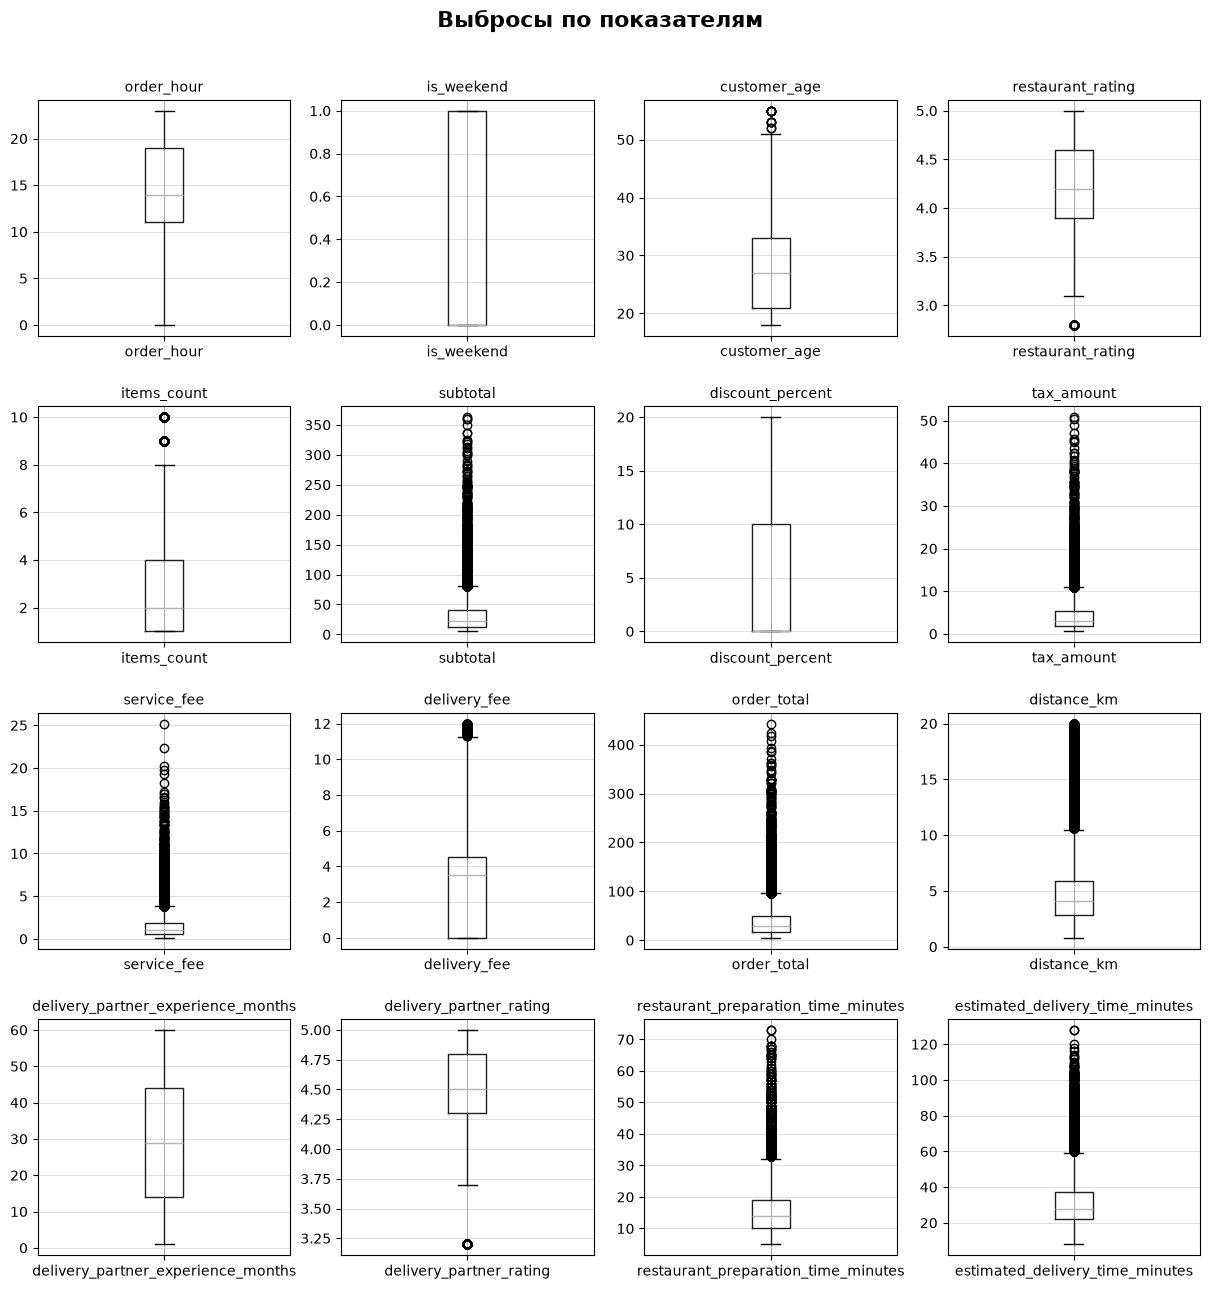

In [15]:
numeric_columns = [
    'order_hour',
    'is_weekend',
    'customer_age',
    'restaurant_rating',
    'items_count',
    'subtotal',
    'discount_percent',
    'tax_amount',
    'service_fee',
    'delivery_fee',
    'order_total',
    'distance_km',
    'delivery_partner_experience_months',
    'delivery_partner_rating',
    'restaurant_preparation_time_minutes',
    'estimated_delivery_time_minutes',
]

fig, axes = plt.subplots(4, 4, figsize=(15, 15))
axes = axes.flatten()

for idx, col in enumerate(numeric_columns):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax)
    ax.set_xlabel('')
    ax.set_title(col, fontsize=10)
    ax.grid(axis="y", alpha=0.4)

plt.suptitle('Выбросы по показателям', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.2,
    hspace=0.3
)
plt.show()

**Вывод:** Есть большое количество выбросов по финансовым показателям, расстоянию и времени. Но это реальные кейсы - большие заказы, которые просто выделяются среди большинства других заказов

## **Одномерный анализ**

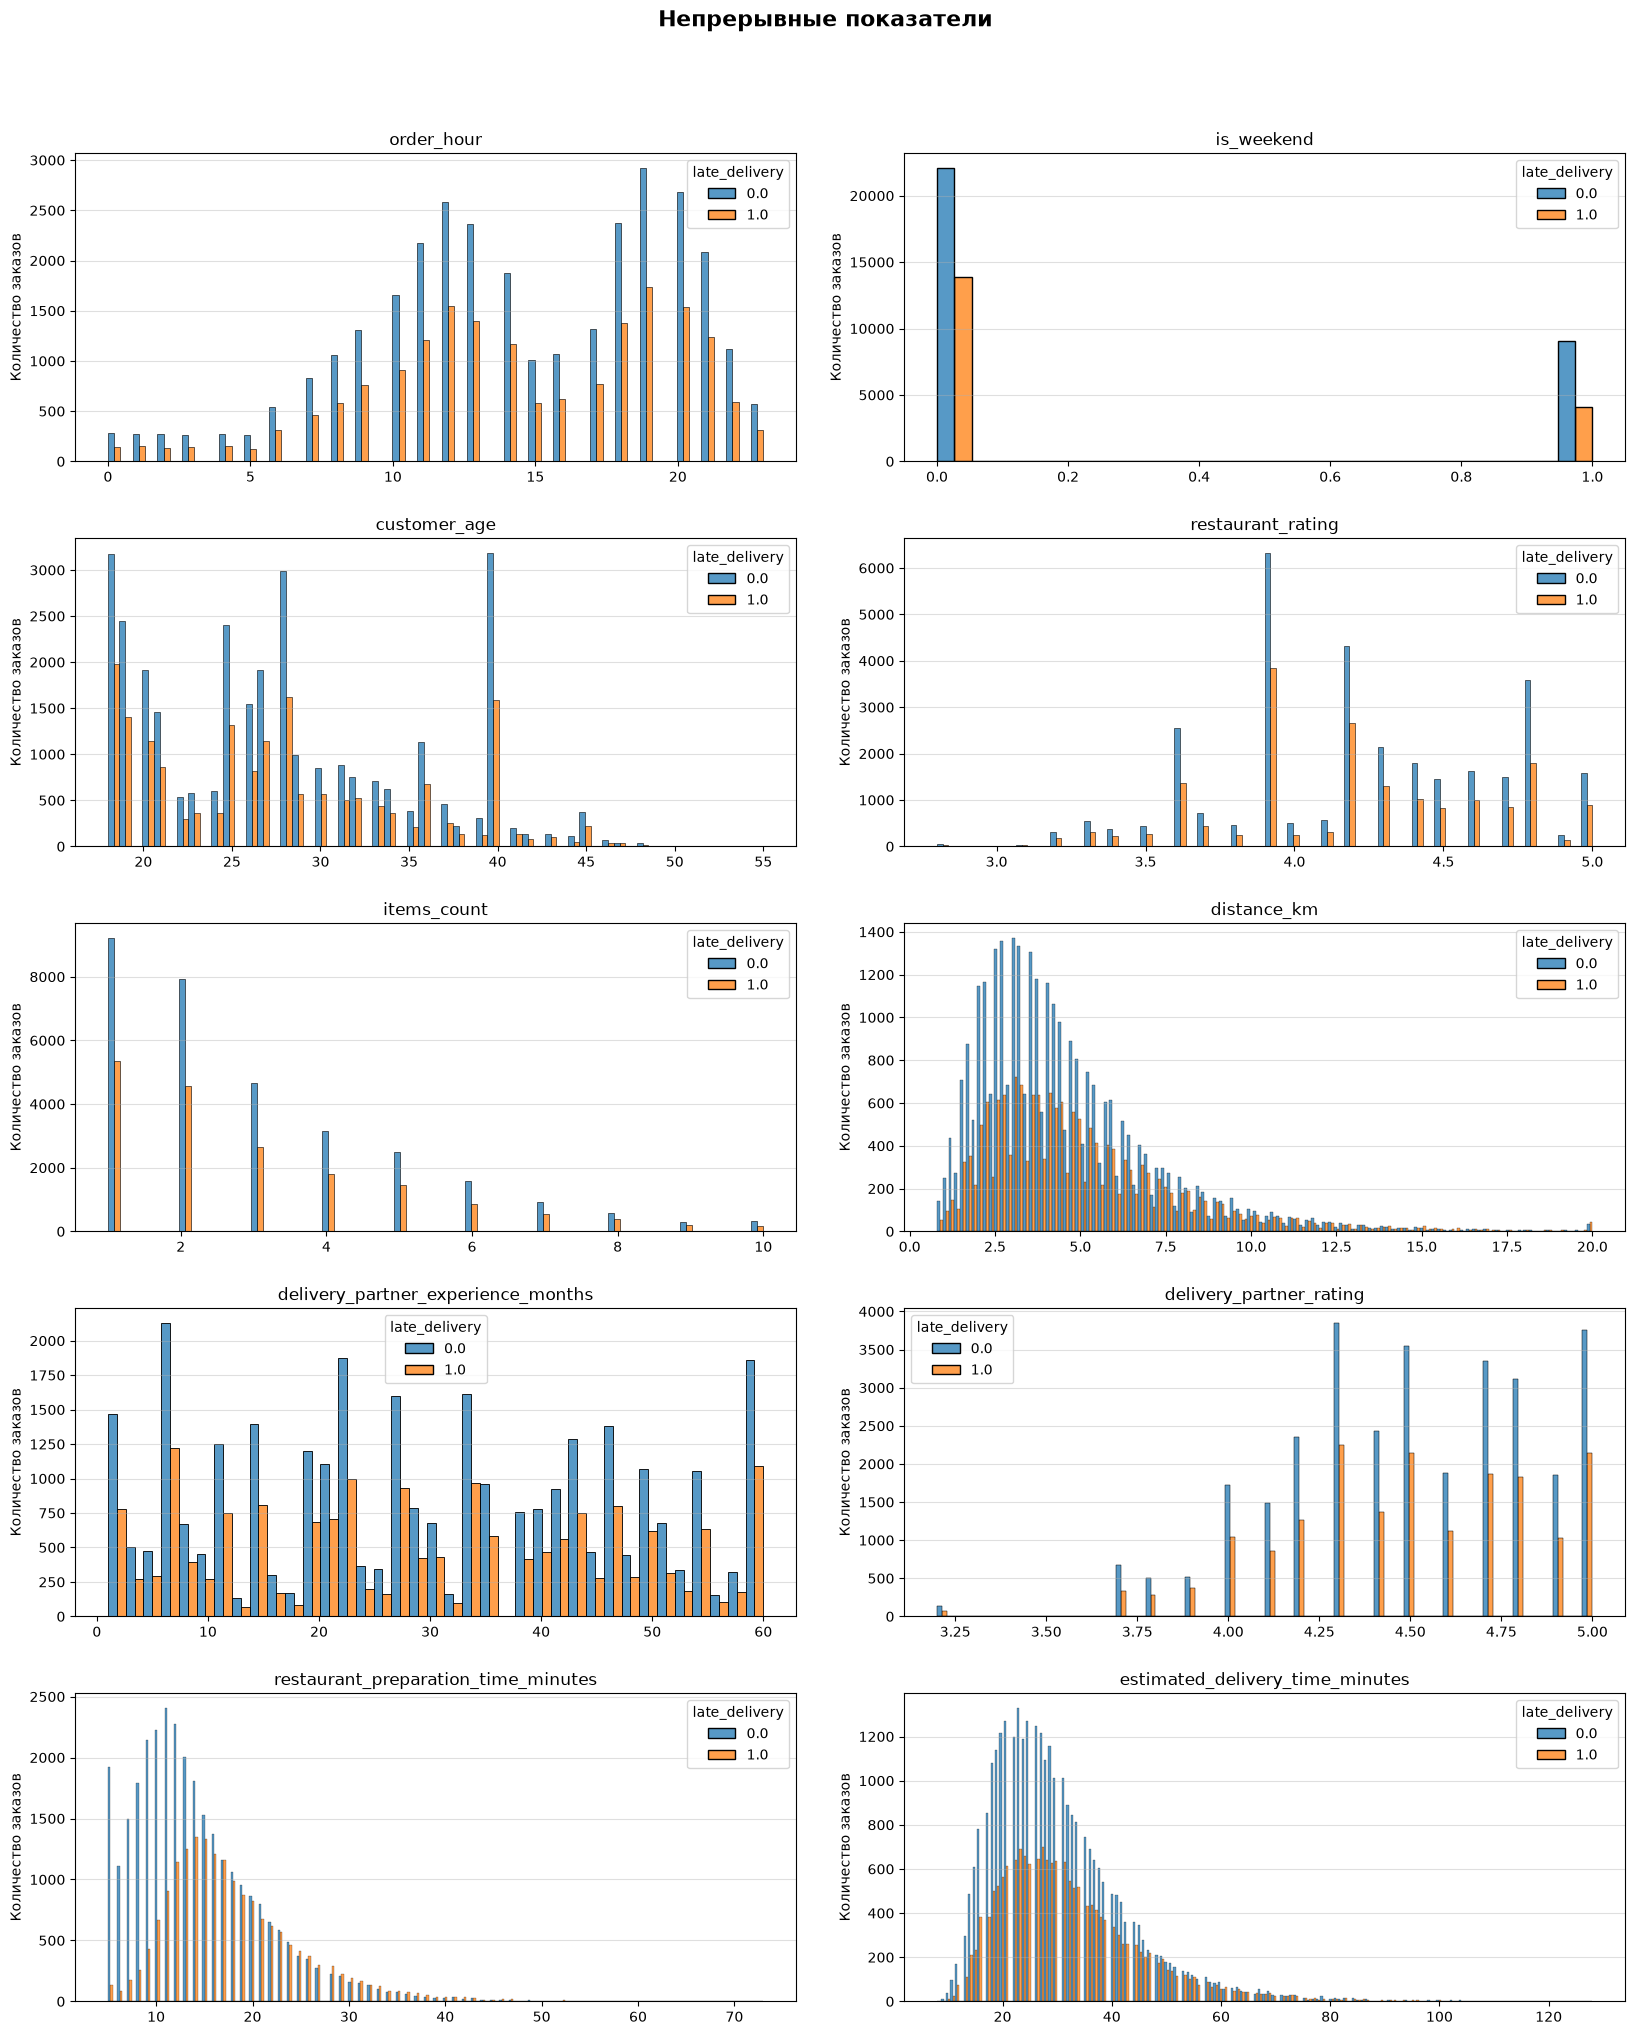

In [16]:
numeric_columns = [
    'order_hour',
    'is_weekend',
    'customer_age',
    'restaurant_rating',
    'items_count',
    'distance_km',
    'delivery_partner_experience_months',
    'delivery_partner_rating',
    'restaurant_preparation_time_minutes',
    'estimated_delivery_time_minutes',
]

fig, axes = plt.subplots(5, 2, figsize=(20, 24))
axes = axes.flatten()

for idx, col in enumerate(numeric_columns):
    ax = axes[idx]
    sns.histplot(
        data=df,
        x=col,
        hue='late_delivery',
        bins="auto",
        multiple='dodge',
        ax=ax
    )
    ax.set_xlabel('')
    ax.set_ylabel("Количество заказов")
    ax.set_title(col, fontsize=12)
    ax.grid(axis="y", alpha=.4)

plt.suptitle('Непрерывные показатели', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.15,
    hspace=0.25
)
plt.show()

Показатели которые стоит рассмотреть подробнее:  
- **distance_km**  
- **order_hour**  
- **restaurant_preparation_time_minutes**  

### % Опозданий в зависимости от расстояния (distance_km)

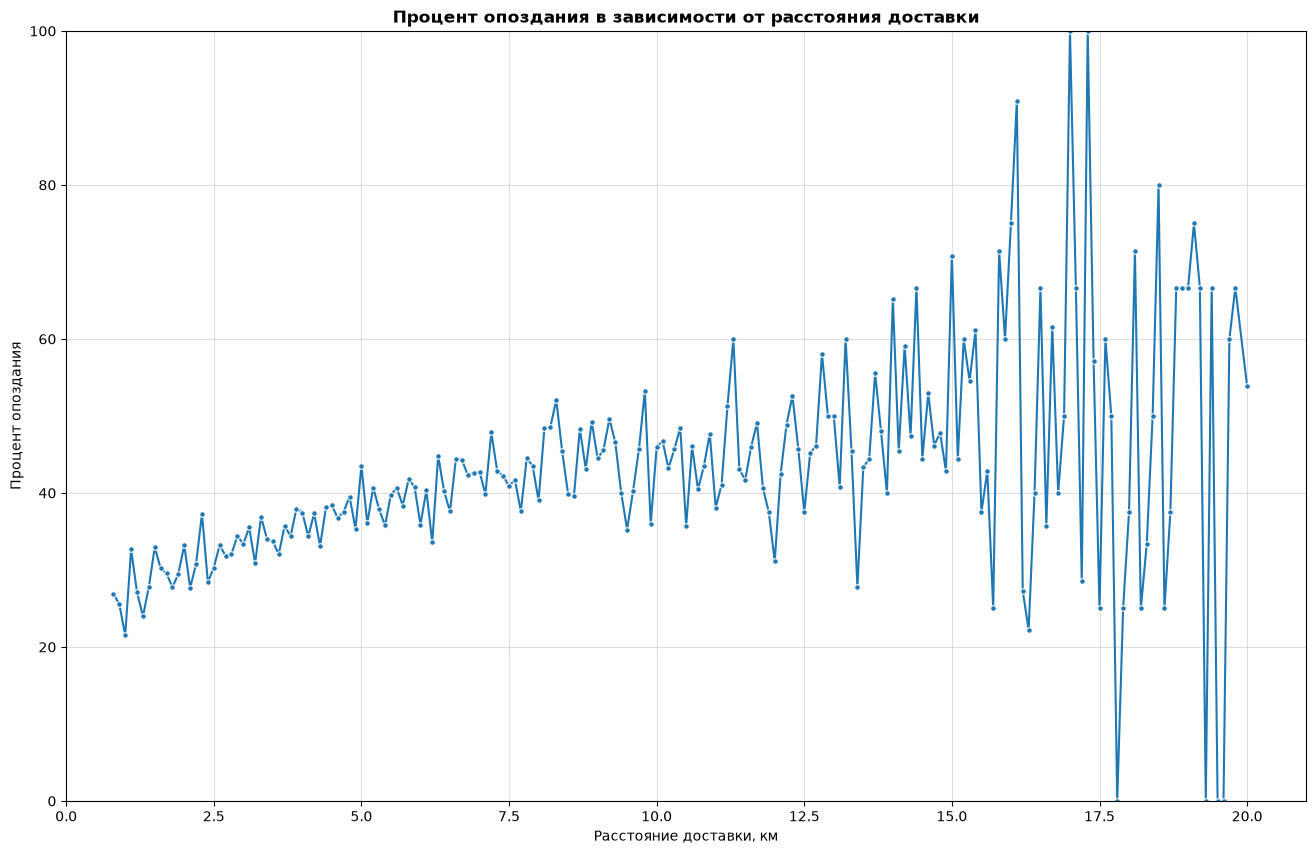

In [17]:
distance_km = df.groupby("distance_km").agg(
    orders_count=("distance_km", "count"),
    late_delevery_percent=("late_delivery", "mean")
).reset_index()

distance_km["late_delevery_percent"] = distance_km["late_delevery_percent"] * 100

fig, ax = plt.subplots(figsize=(16, 10))

sns.lineplot(
    data=distance_km,
    x="distance_km",
    y="late_delevery_percent",
    marker="o", markersize=4
)

ax.grid(alpha=.4)
ax.set_ylim(0, 100)
ax.set_xlim(0, 21)
ax.set_xlabel('Расстояние доставки, км')
ax.set_ylabel('Процент опоздания')
ax.set_title("Процент опоздания в зависимости от расстояния доставки", fontsize=12, fontweight='bold')

plt.show()

**Вывод:** При увеличении дистанции растет процент опозданий. Примерно с 10 км график становится хаотичным, что может сказаться на прогнозировании

### % Опозданий в зависимости от времени заказа (order_hour)

Разница между максимальным и минимальным % опозданий: 6


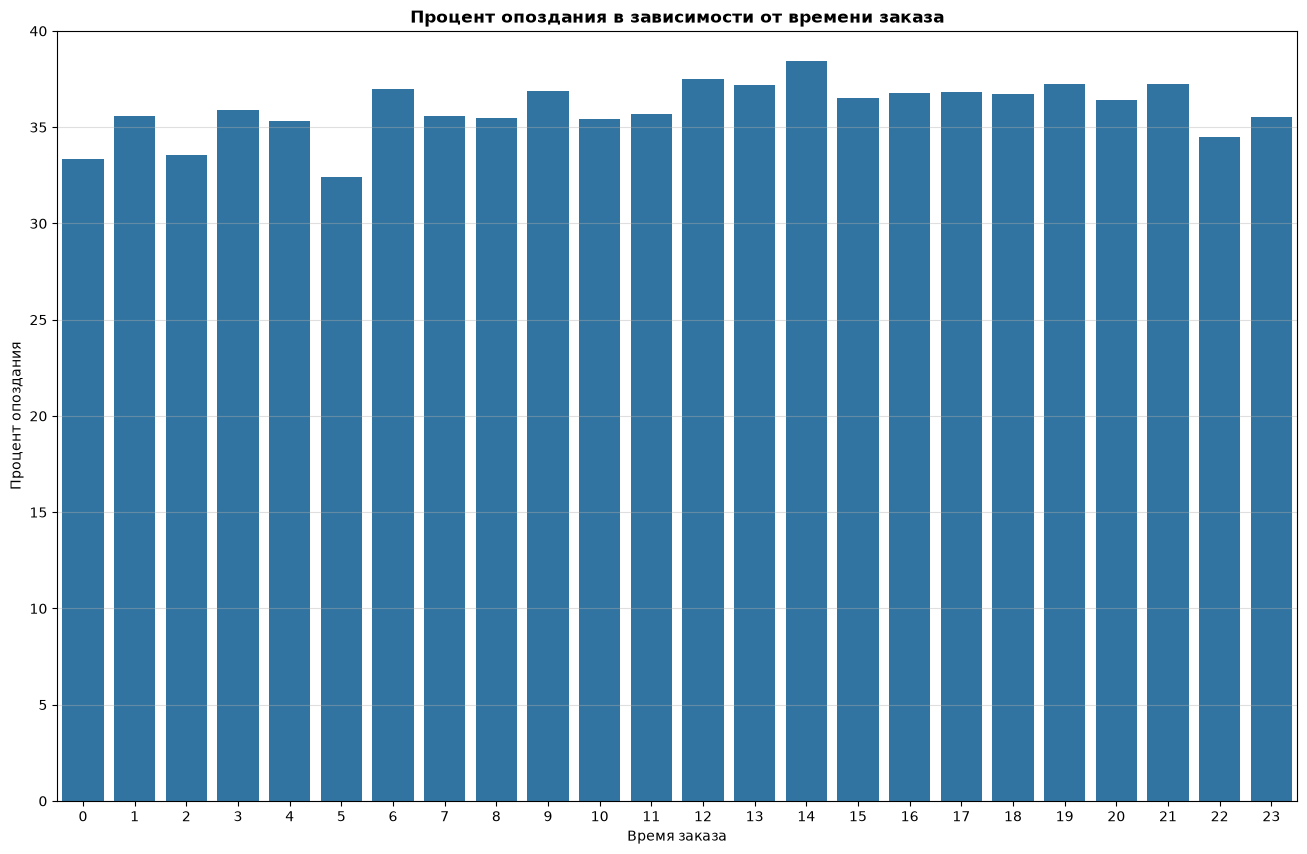

In [18]:
order_hour = df.groupby("order_hour").agg(
    orders_count=("order_hour", "count"),
    late_delevery_percent=("late_delivery", "mean")
).reset_index()

print(f"Разница между максимальным и минимальным % опозданий: {(order_hour["late_delevery_percent"].max() - order_hour["late_delevery_percent"].min()) * 100:.0f}")

order_hour["late_delevery_percent"] = order_hour["late_delevery_percent"] * 100

fig, ax = plt.subplots(figsize=(16, 10))

sns.barplot(
    data=order_hour,
    x="order_hour",
    y="late_delevery_percent",
    legend=False
)

ax.grid(axis="y", alpha=0.4)
ax.set_ylim(0, 40)
ax.set_xlabel('Время заказа')
ax.set_ylabel('Процент опоздания')
ax.set_title("Процент опоздания в зависимости от времени заказа", fontsize=12, fontweight='bold')

plt.show()

**Вывод:** Время заказа слабо влияет на процент опоздания

### % Опозданий в зависимости от времени приготовления (restaurant_preparation_time_minutes)

Разница между максимальным и минимальным % опозданий: 100


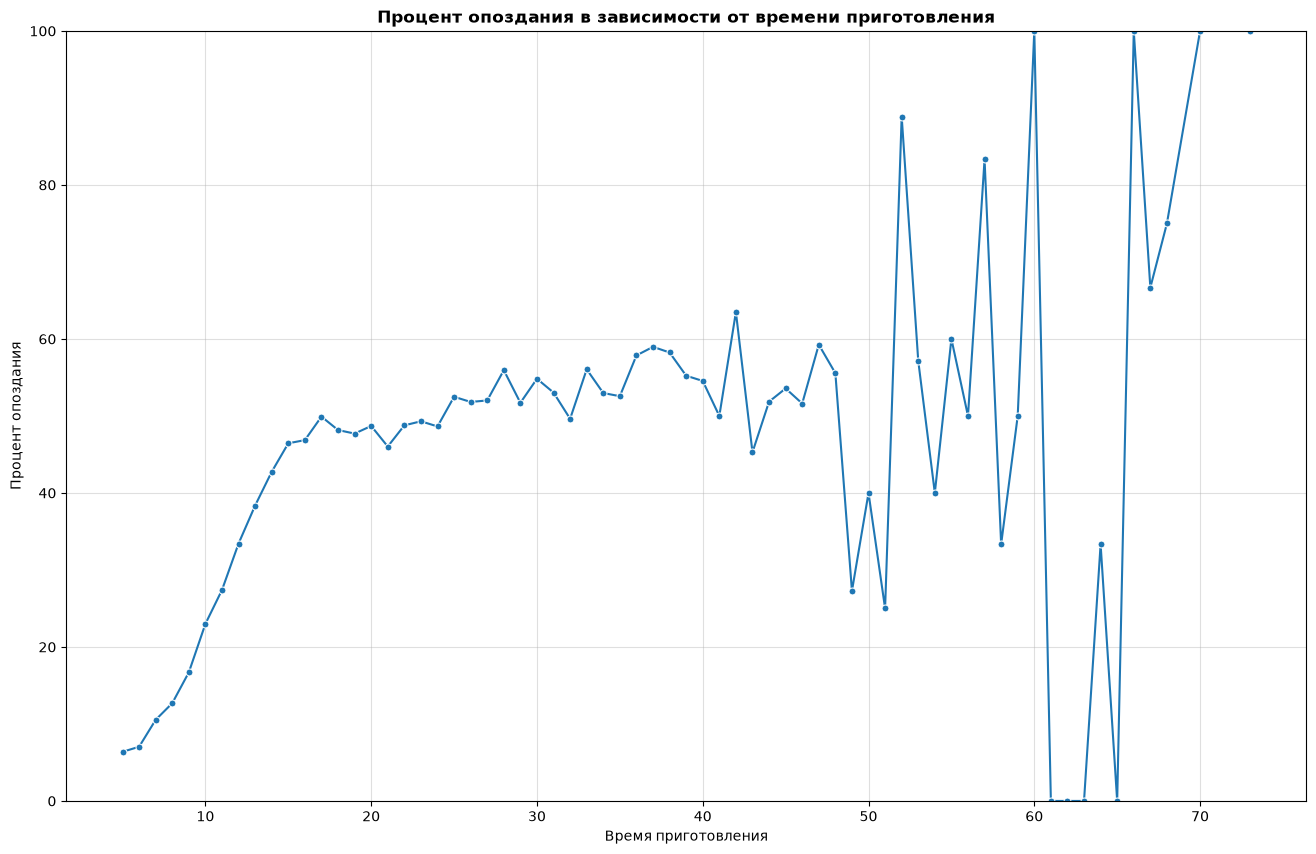

In [19]:
restaurant_preparation_time_minutes = df.groupby("restaurant_preparation_time_minutes").agg(
    orders_count=("restaurant_preparation_time_minutes", "count"),
    late_delevery_percent=("late_delivery", "mean")
).reset_index()

print(f"Разница между максимальным и минимальным % опозданий: {(restaurant_preparation_time_minutes["late_delevery_percent"].max() - restaurant_preparation_time_minutes["late_delevery_percent"].min()) * 100:.0f}")

restaurant_preparation_time_minutes["late_delevery_percent"] = restaurant_preparation_time_minutes["late_delevery_percent"] * 100

fig, ax = plt.subplots(figsize=(16, 10))

sns.lineplot(
    data=restaurant_preparation_time_minutes,
    x="restaurant_preparation_time_minutes",
    y="late_delevery_percent",
    legend=False,
    marker="o", markersize=5
)

ax.grid(alpha=.4)
ax.set_ylim(0, 100)
ax.set_xlabel('Время приготовления')
ax.set_ylabel('Процент опоздания')
ax.set_title("Процент опоздания в зависимости от времени приготовления", fontsize=12, fontweight='bold')

plt.show()

**Вывод:** Время приготовления сильно влияет на процент опоздания. При приготовлении от 15 минут процент опоздания будет примерно 50%. При приготовдении от 49 минут график становится хаотичным, местами процент опоздания доходит до 100%, скорей всего это связано с маленьким количеством записей, это может сказаться на прогнозировании

### % Опозданий в зависимости от рейтинга курьера (delivery_partner_rating)

Разница между максимальным и минимальным % опозданий: 8


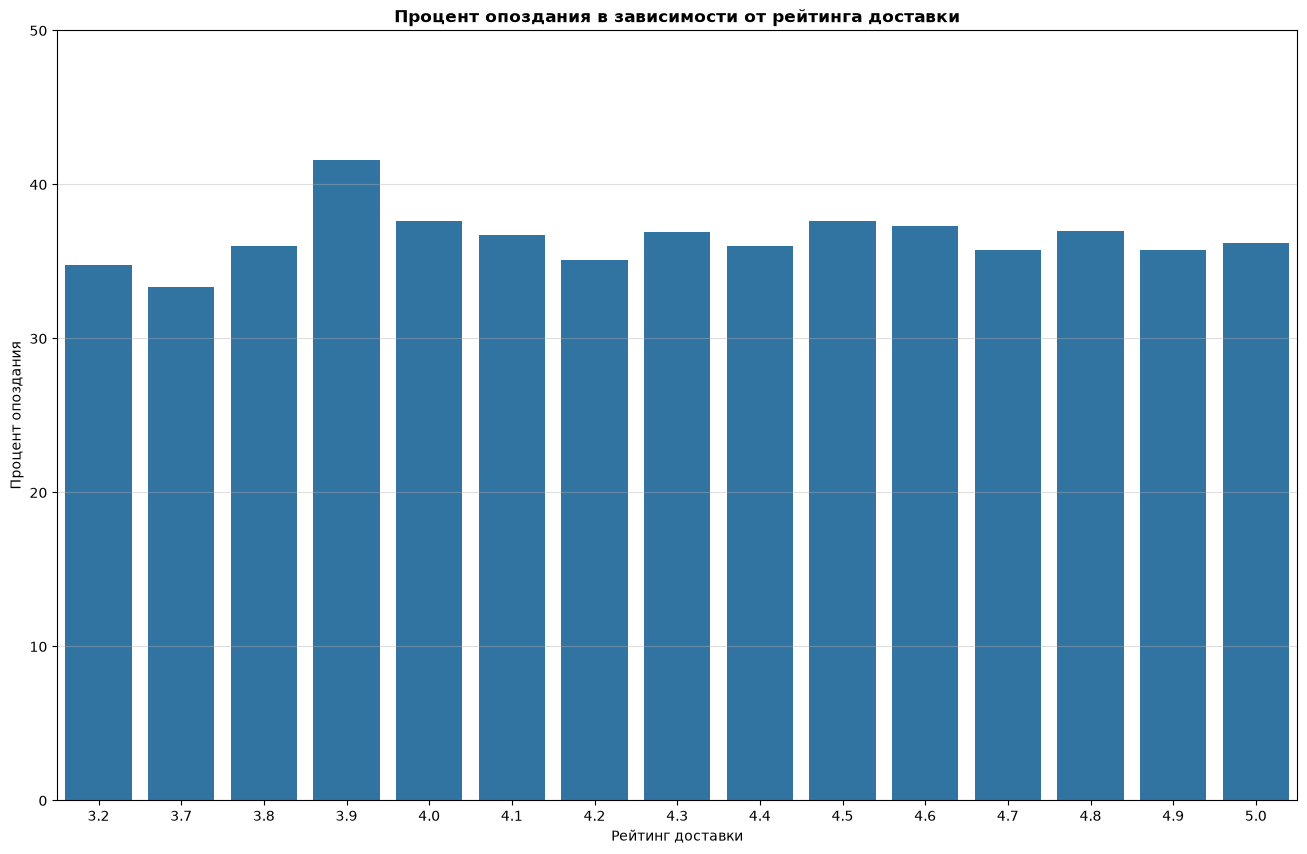

In [20]:
delivery_partner_rating = df.groupby("delivery_partner_rating").agg(
    orders_count=("delivery_partner_rating", "count"),
    late_delevery_percent=("late_delivery", "mean")
).reset_index()

print(f"Разница между максимальным и минимальным % опозданий: {(delivery_partner_rating["late_delevery_percent"].max() - delivery_partner_rating["late_delevery_percent"].min()) * 100:.0f}")

delivery_partner_rating["late_delevery_percent"] = delivery_partner_rating["late_delevery_percent"] * 100

fig, ax = plt.subplots(figsize=(16, 10))

sns.barplot(
    data=delivery_partner_rating,
    x="delivery_partner_rating",
    y="late_delevery_percent",
    legend=False
)

ax.grid(axis="y", alpha=0.4)
ax.set_ylim(0, 50)
ax.set_xlabel('Рейтинг доставки')
ax.set_ylabel('Процент опоздания')
ax.set_title("Процент опоздания в зависимости от рейтинга доставки", fontsize=12, fontweight='bold')

plt.show()

**Вывод:** По графику видно что рейтинг курьера слабо влияет на процент опоздания доставки. Средний процент опозданий для всех рейтингов находится примерно на одном уровне. Слабое влияние на целевой признак

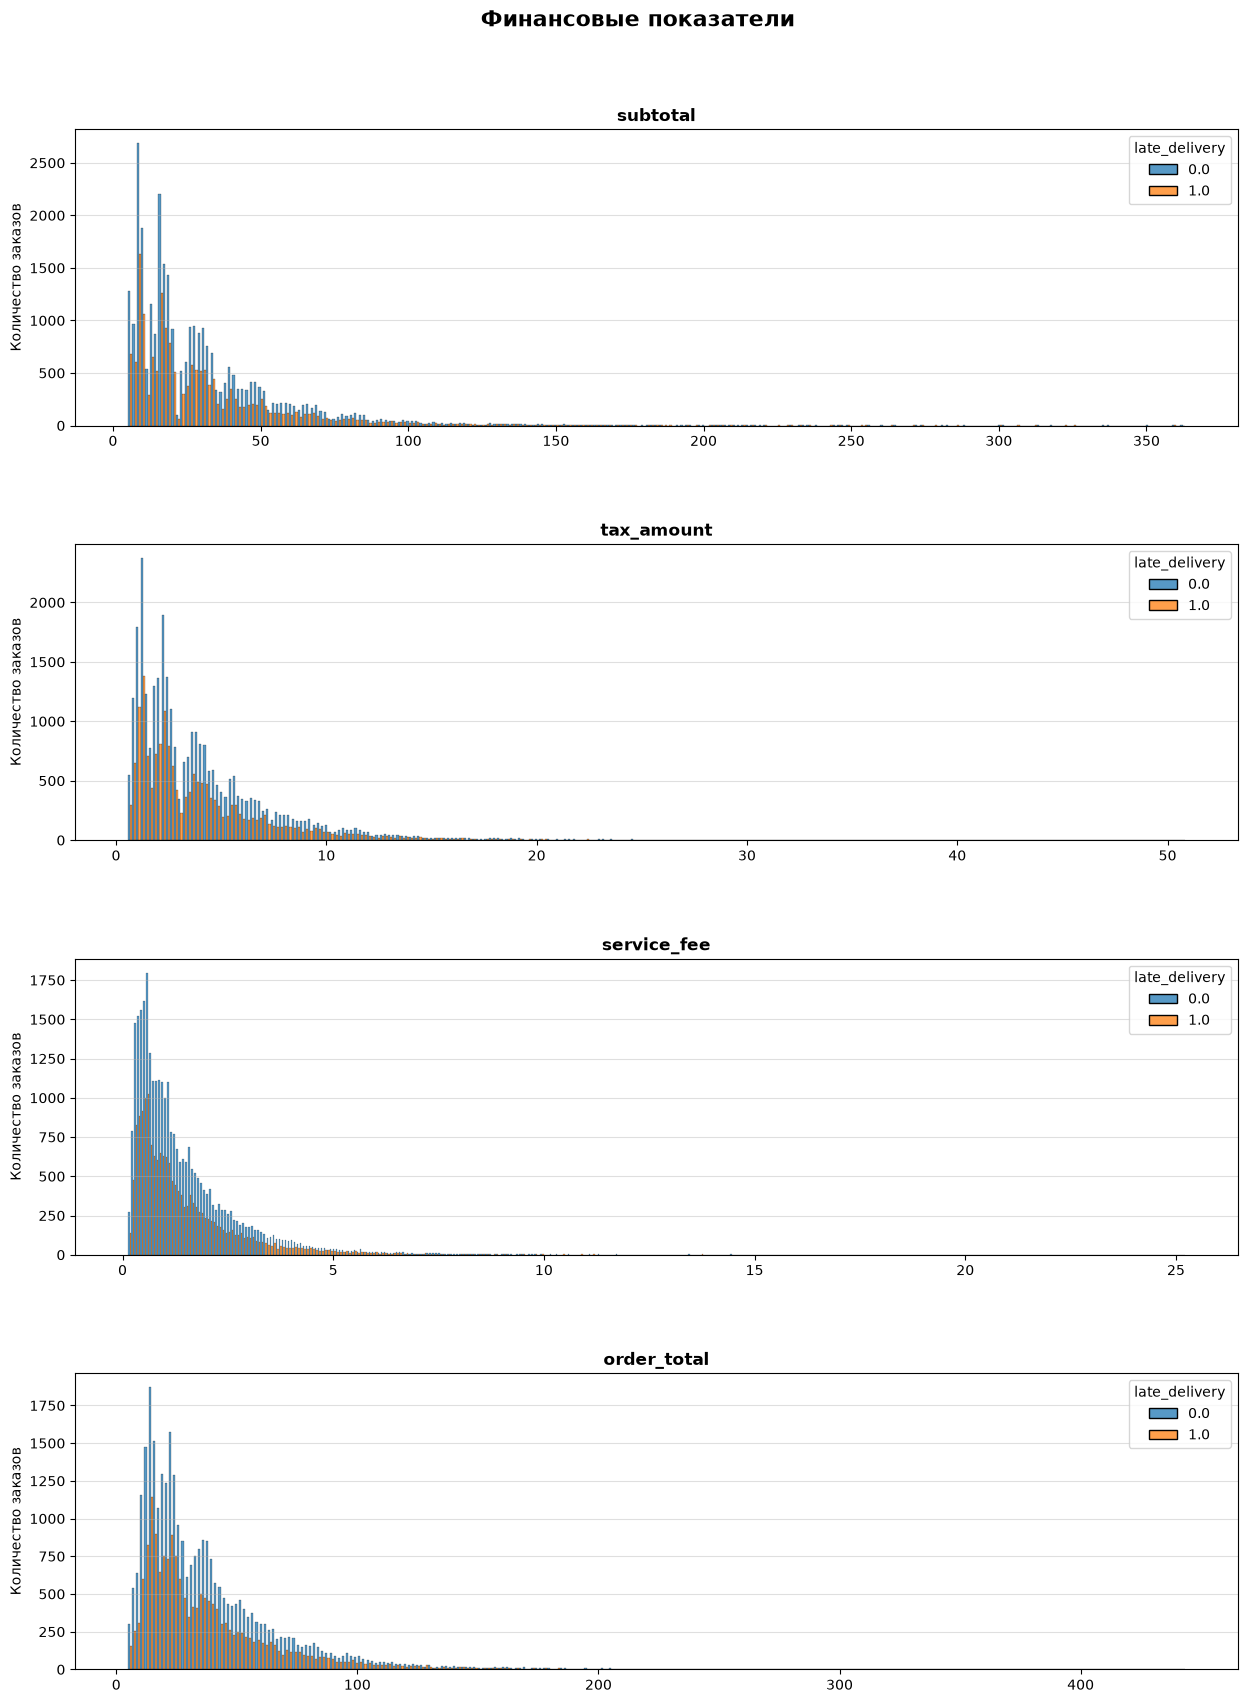

In [21]:
numeric_columns = [
    'subtotal',
    'tax_amount',
    'service_fee',
    'order_total',
]

fig, axes = plt.subplots(4, 1, figsize=(15, 20))
axes = axes.flatten()

for idx, col in enumerate(numeric_columns):
    ax = axes[idx]
    sns.histplot(
        data=df,
        x=col,
        hue='late_delivery',
        bins="auto",
        multiple='dodge',
        ax=ax
    )
    ax.set_xlabel('')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.grid(axis="y", alpha=0.4)
    ax.set_ylabel('Количество заказов')

plt.suptitle('Финансовые показатели', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.2,
    hspace=0.4
)
plt.show()

**Вывод:** по графикам пожно сказать что графики совпадают по распределению опозданий и выполненных заказов в срок

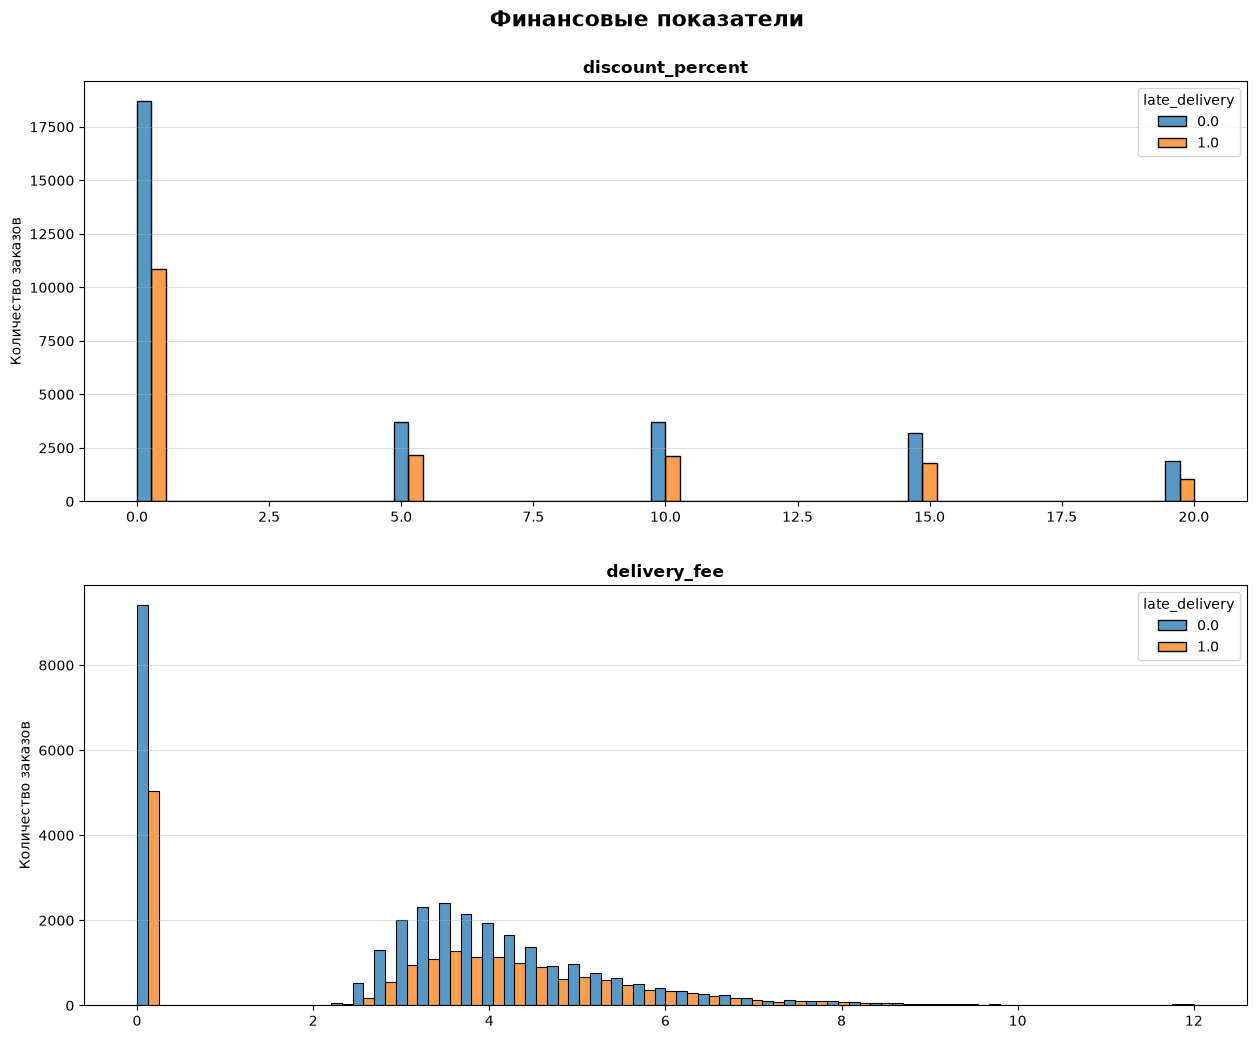

In [22]:
numeric_columns = [
    'discount_percent',
    'delivery_fee'
]

fig, axes = plt.subplots(2, 1, figsize=(15, 12))
axes = axes.flatten()

for idx, col in enumerate(numeric_columns):
    ax = axes[idx]
    sns.histplot(
        data=df,
        x=col,
        hue='late_delivery',
        bins="auto",
        multiple='dodge',
        ax=ax
    )
    ax.set_xlabel('')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.grid(axis="y", alpha=0.4)
    ax.set_ylabel('Количество заказов')

plt.suptitle('Финансовые показатели', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.2,
    hspace=0.2
)
plt.show()

Интересным тут является диапазон от 5 и до конца на графике delivery_fee. В этом диапазоне доля опозданий увеличивается

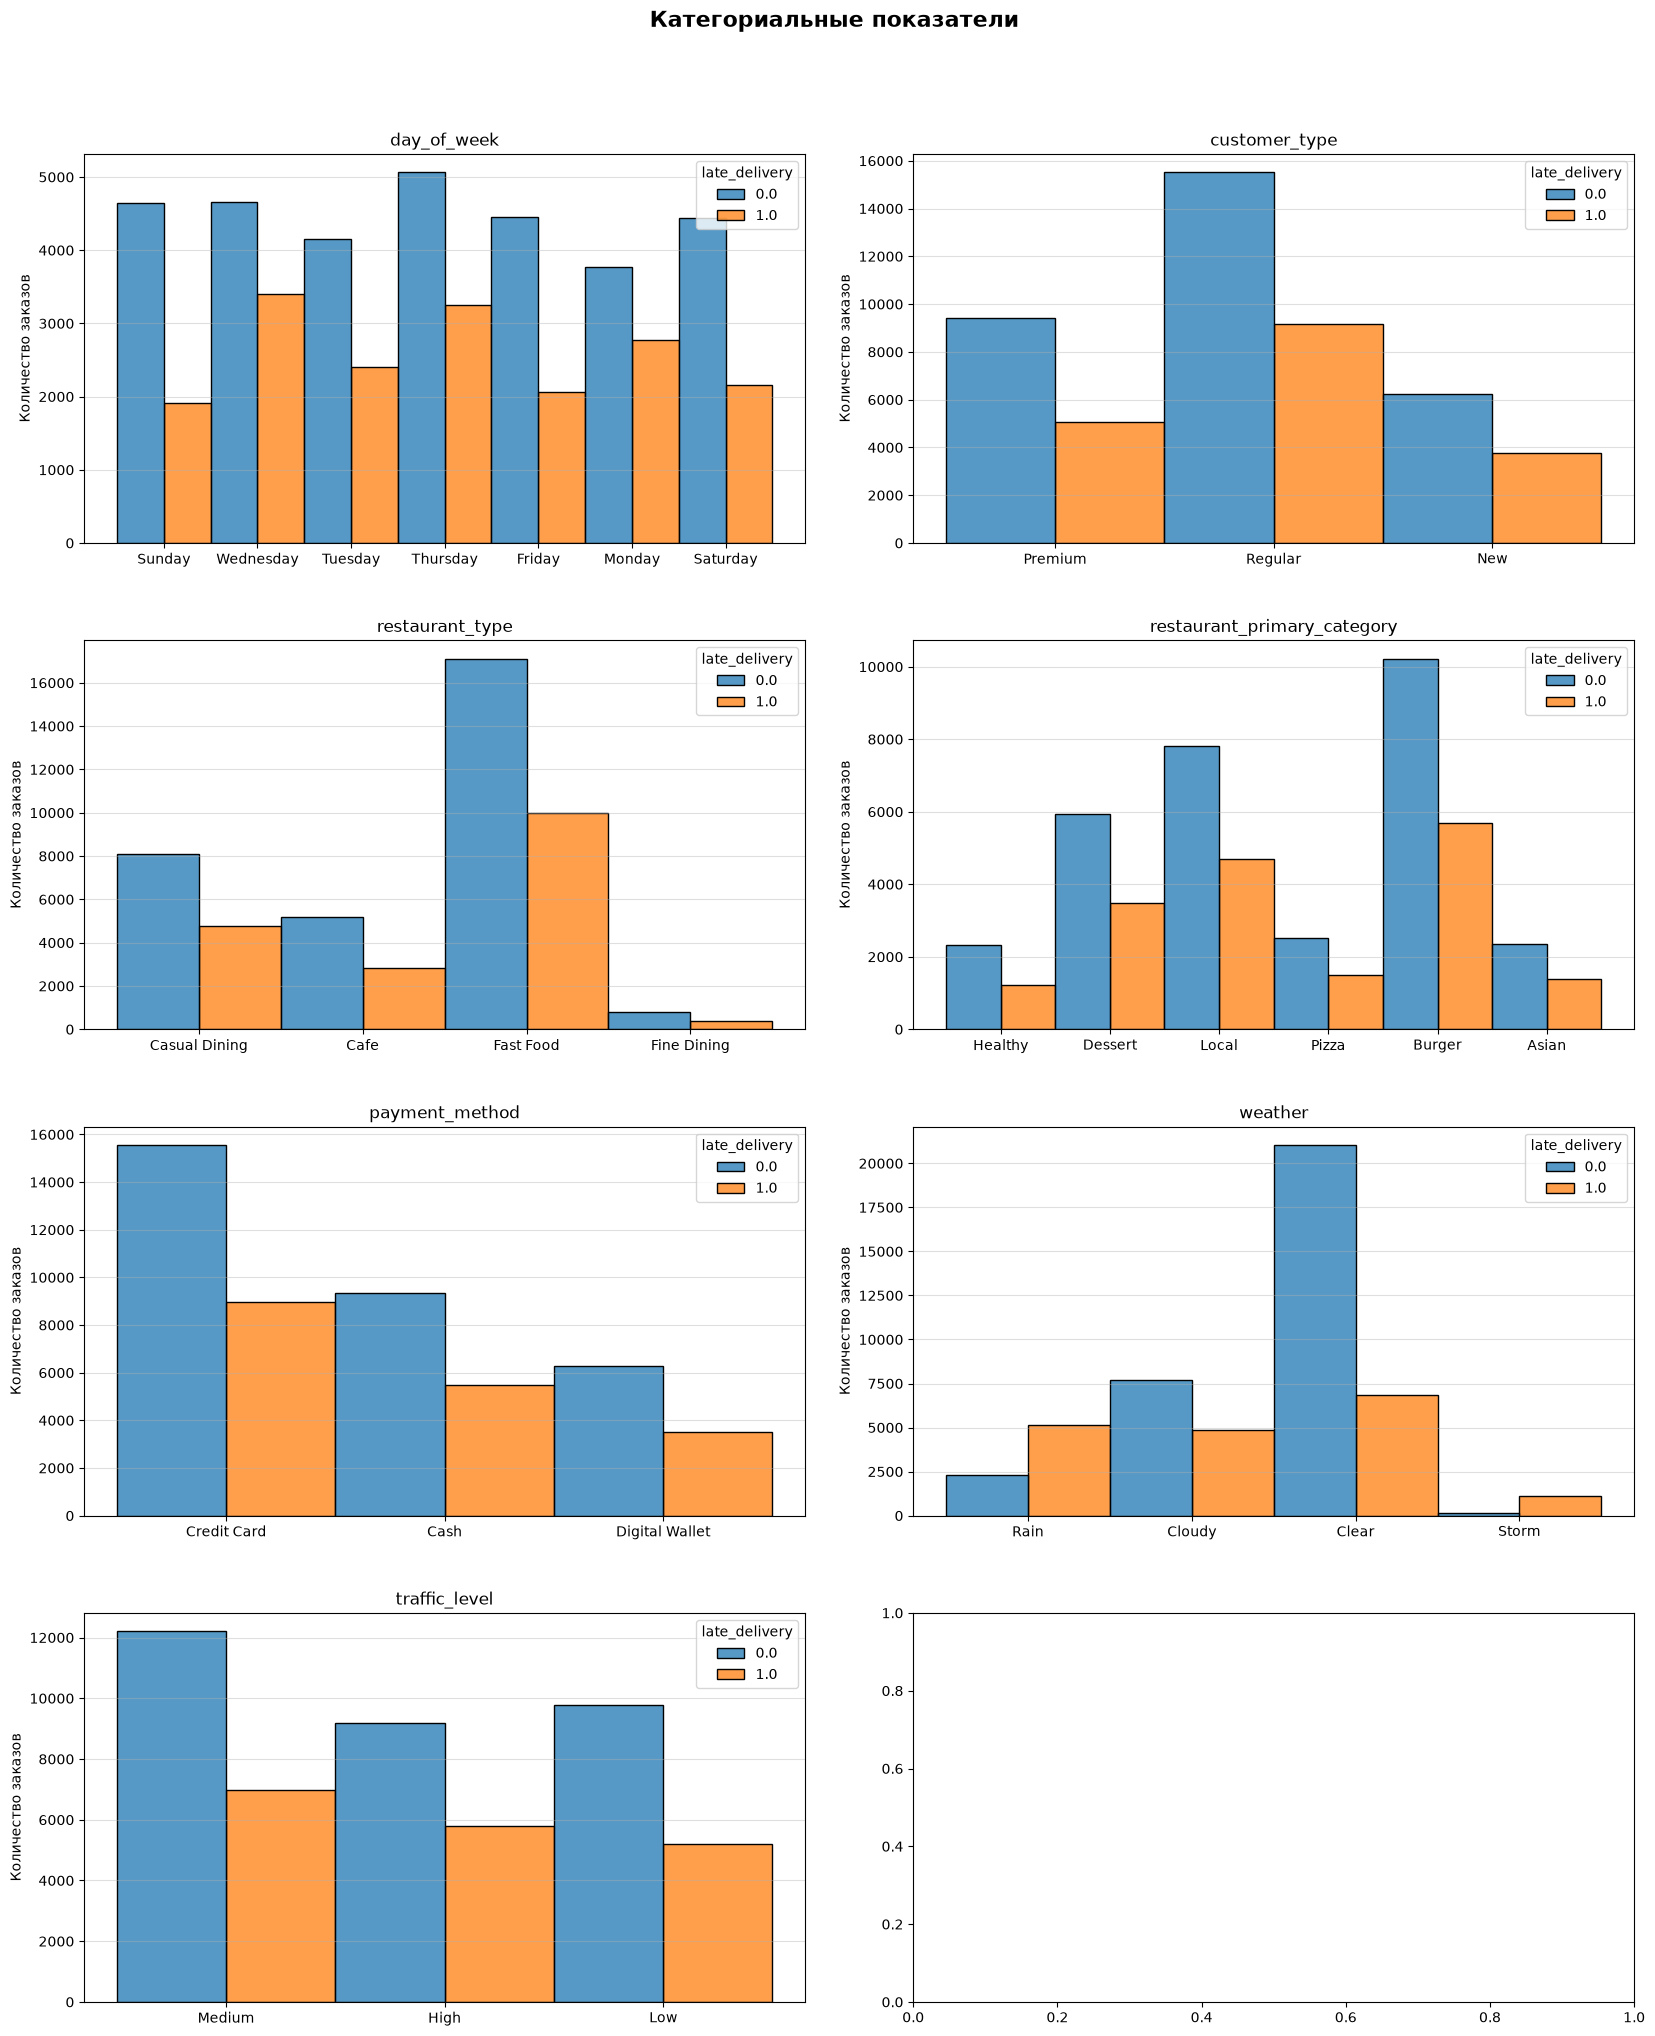

In [23]:
str_columns = [
    'day_of_week',
    'customer_type',
    'restaurant_type',
    'restaurant_primary_category',
    'payment_method',
    'weather',
    'traffic_level',
]

fig, axes = plt.subplots(4, 2, figsize=(20, 24))
axes = axes.flatten()

for idx, col in enumerate(str_columns):
    ax = axes[idx]
    sns.histplot(
        data=df,
        x=col,
        hue='late_delivery',
        bins="auto",
        multiple='dodge',
        ax=ax
    )
    ax.set_xlabel('')
    ax.set_ylabel("Количество заказов")
    ax.set_title(col, fontsize=12)
    ax.grid(axis="y", alpha=.4)

plt.suptitle('Категориальные показатели', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.15,
    hspace=0.25
)
plt.show()

Показатели которые стоит рассмотреть подробнее:  
- **day_of_week**  
- **weather**  
- **traffic_level**  

### % Опозданий в пробки (traffic_level)

Разница между максимальным и минимальным % опозданий: 4


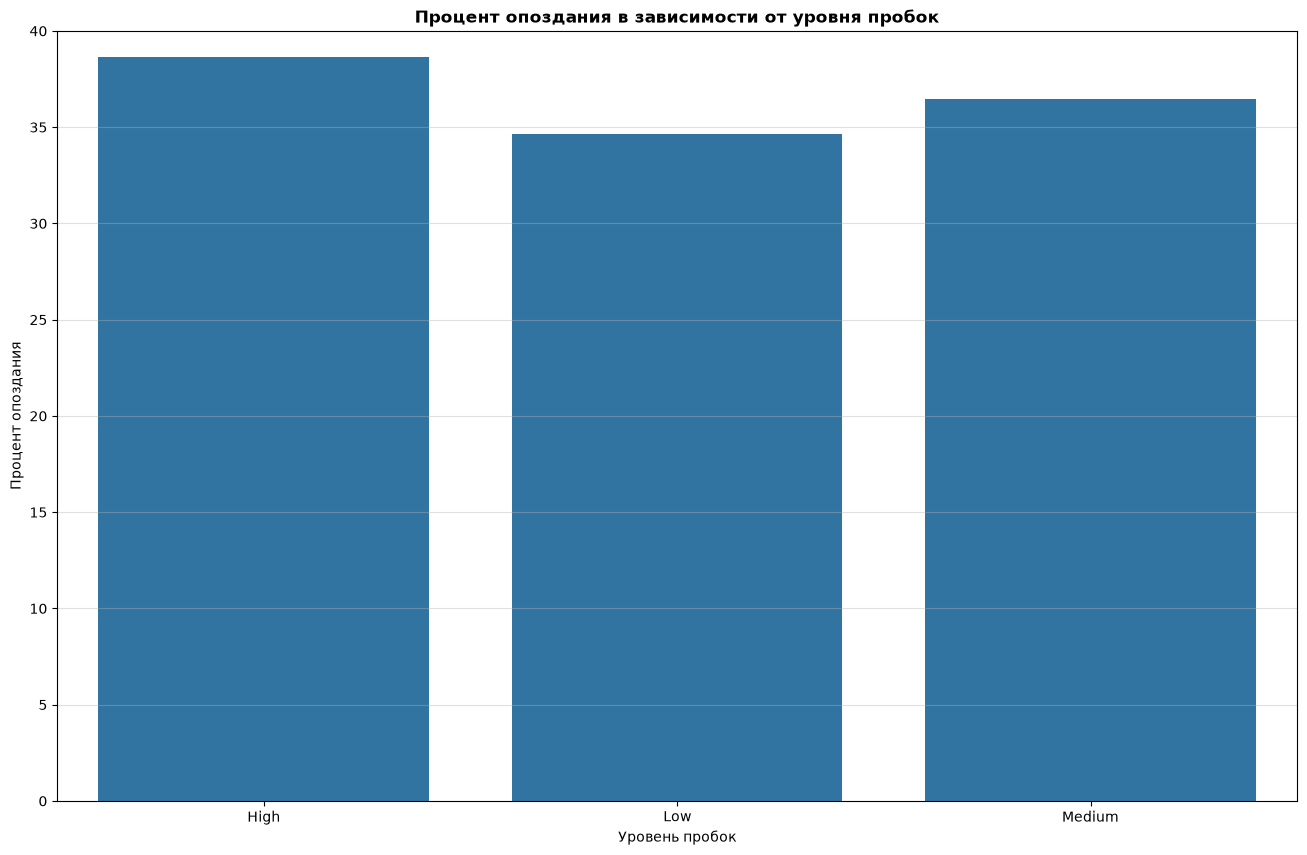

In [24]:
traffic_level = df.groupby("traffic_level").agg(
    orders_count=("traffic_level", "count"),
    late_delevery_percent=("late_delivery", "mean")
).reset_index()

print(f"Разница между максимальным и минимальным % опозданий: {(traffic_level["late_delevery_percent"].max() - traffic_level["late_delevery_percent"].min()) * 100:.0f}")

traffic_level["late_delevery_percent"] = traffic_level["late_delevery_percent"] * 100

fig, ax = plt.subplots(figsize=(16, 10))

sns.barplot(
    data=traffic_level.head(25),
    x="traffic_level",
    y="late_delevery_percent",
    legend=False
)
ax.grid(axis="y", alpha=0.4)
ax.set_ylim(0, 40)
ax.set_xlabel('Уровень пробок')
ax.set_ylabel('Процент опоздания')
ax.set_title("Процент опоздания в зависимости от уровня пробок", fontsize=12, fontweight='bold')

plt.show()

**Вывод:** Пробки слабо влияют на процент опоздания

### % Опозданий в погоду (weather)

Разница между максимальным и минимальным % опозданий: 65


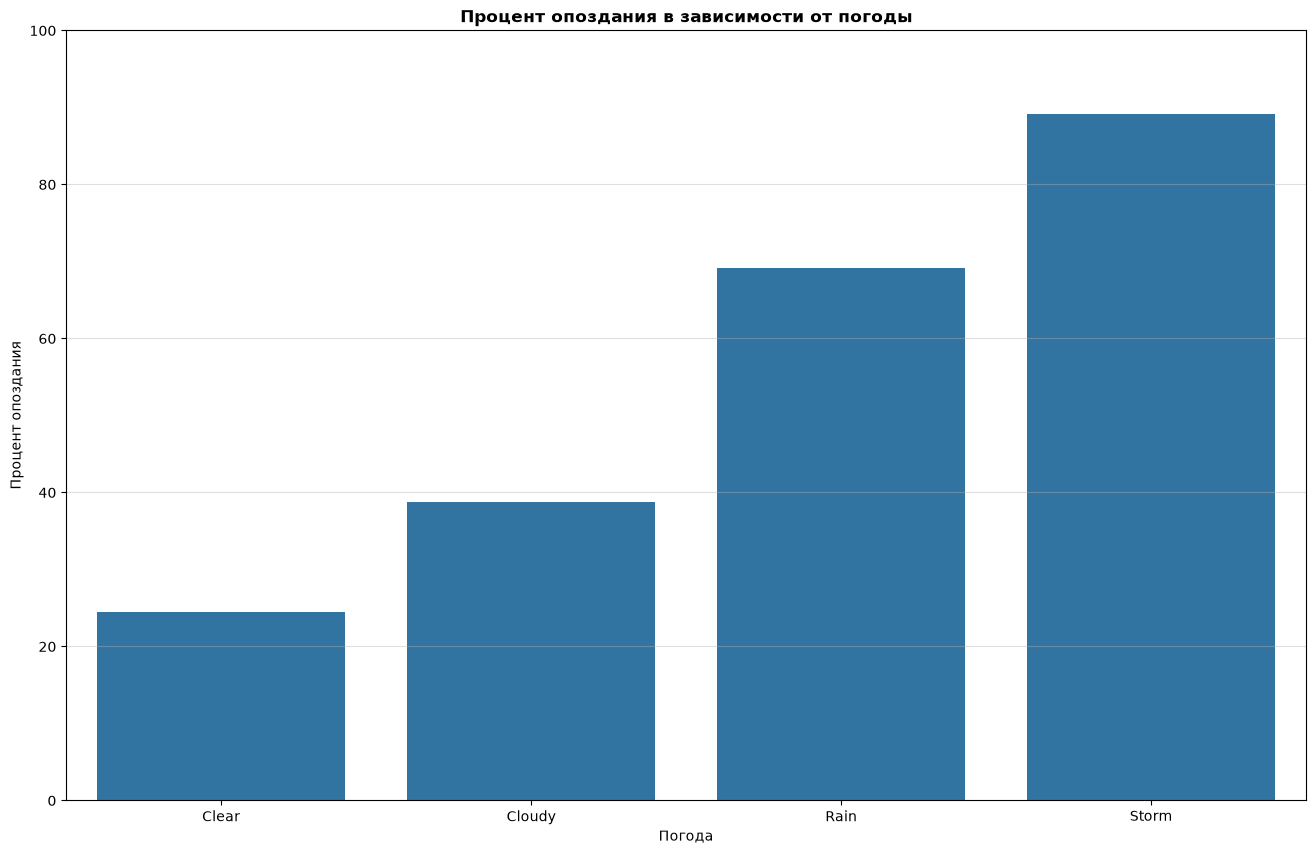

In [25]:
weather = df.groupby("weather").agg(
    orders_count=("weather", "count"),
    late_delevery_percent=("late_delivery", "mean")
).reset_index()

print(f"Разница между максимальным и минимальным % опозданий: {(weather["late_delevery_percent"].max() - weather["late_delevery_percent"].min()) * 100:.0f}")

weather["late_delevery_percent"] = weather["late_delevery_percent"] * 100

fig, ax = plt.subplots(figsize=(16, 10))

sns.barplot(
    data=weather.head(25),
    x="weather",
    y="late_delevery_percent",
    legend=False
)

ax.grid(axis="y", alpha=0.4)
ax.set_ylim(0, 100)
ax.set_xlabel('Погода')
ax.set_ylabel('Процент опоздания')
ax.set_title("Процент опоздания в зависимости от погоды", fontsize=12, fontweight='bold')

plt.show()

**Вывод:** Погода сильно влияет на процент опоздания, в ясную погоду процент ниже, в шторм выше. Разница между средним процентом опозданий в чистую погоду и шторм - 65%

### % Опозданий от дня недели (day_of_week)

Разница между максимальным и минимальным % опозданий: 13


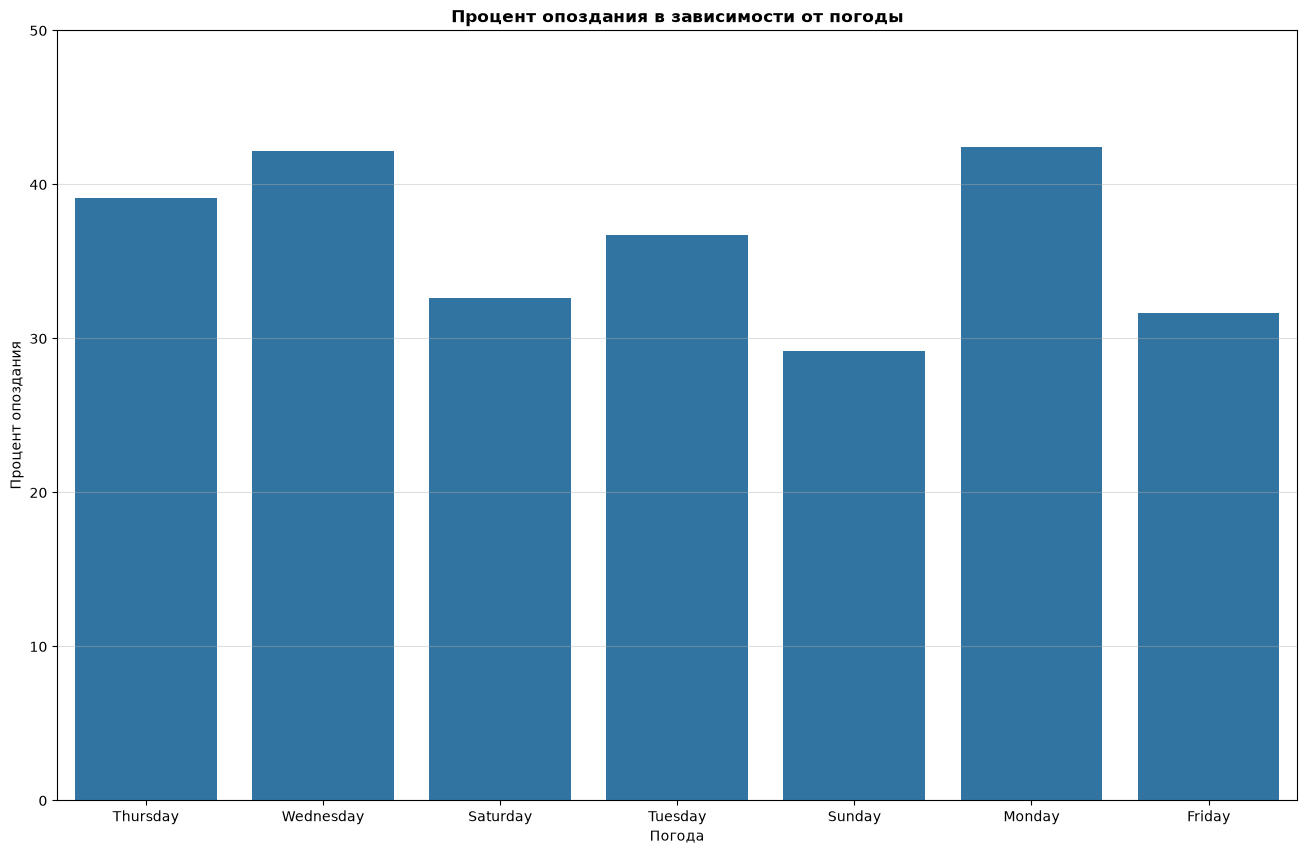

In [26]:
day_of_week = df.groupby("day_of_week").agg(
    orders_count=("day_of_week", "count"),
    late_delevery_percent=("late_delivery", "mean")
).sort_values(by="orders_count", ascending=False).reset_index()

print(f"Разница между максимальным и минимальным % опозданий: {(day_of_week["late_delevery_percent"].max() - day_of_week["late_delevery_percent"].min()) * 100:.0f}")

day_of_week["late_delevery_percent"] = day_of_week["late_delevery_percent"] * 100

fig, ax = plt.subplots(figsize=(16, 10))

sns.barplot(
    data=day_of_week.head(25),
    x="day_of_week",
    y="late_delevery_percent",
    legend=False
)

ax.grid(axis="y", alpha=0.4)
ax.set_ylim(0, 50)
ax.set_xlabel('Погода')
ax.set_ylabel('Процент опоздания')
ax.set_title("Процент опоздания в зависимости от погоды", fontsize=12, fontweight='bold')

plt.show()

**Вывод:** Есть небольшое влияние дня недели на процент опоздания

### % Опозданий в район (delivery_area)

График не вошел в общий subplots, рассмотрим отдельно

Разница между максимальным и минимальным % опозданий: 10


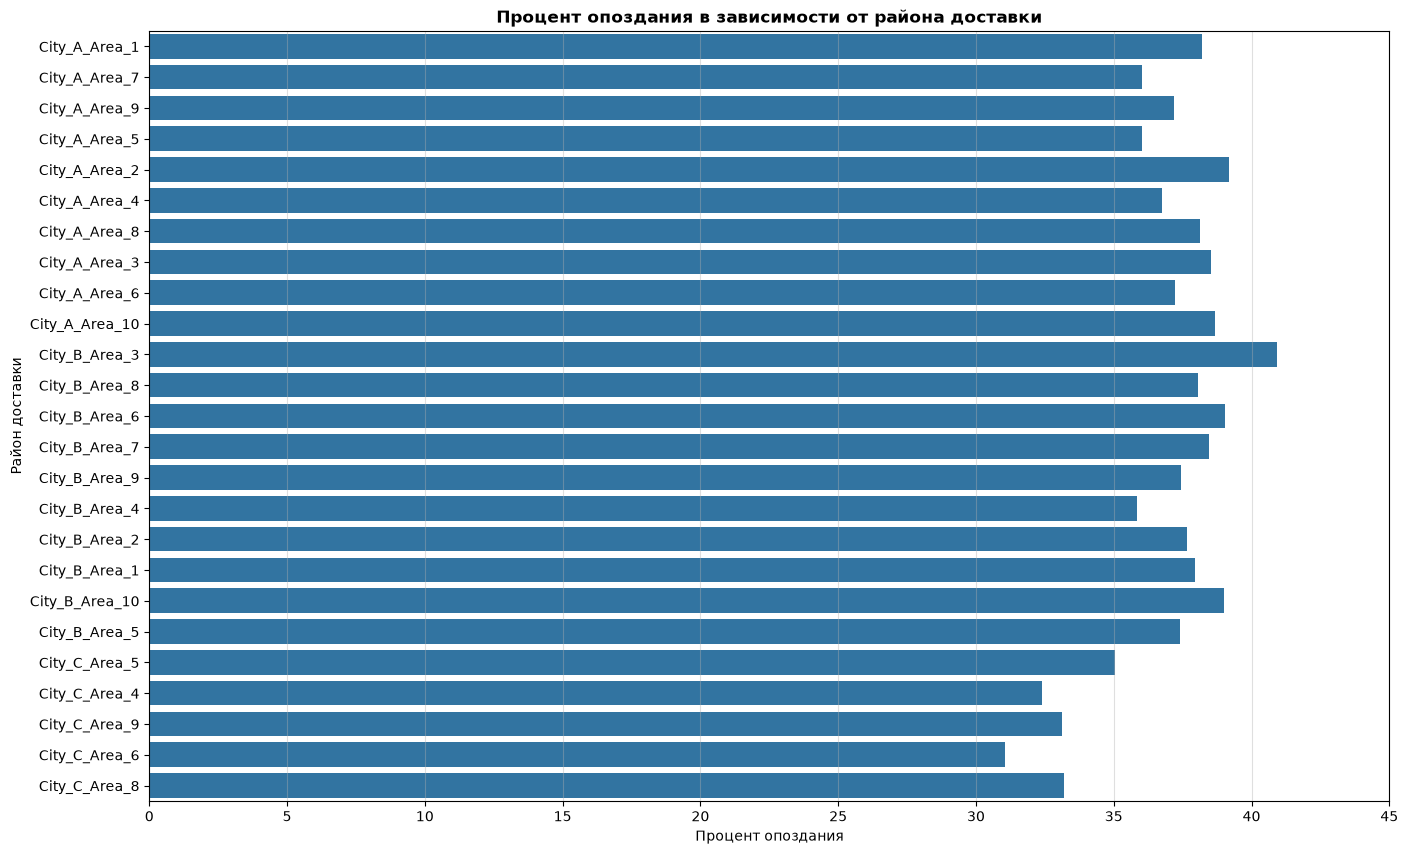

In [27]:
area = df.groupby("delivery_area").agg(
    orders_count=("delivery_area", "count"),
    late_delevery_percent=("late_delivery", "mean")
).sort_values(by="orders_count", ascending=False).reset_index()

print(f"Разница между максимальным и минимальным % опозданий: {(area["late_delevery_percent"].max() - area["late_delevery_percent"].min()) * 100:.0f}")

area["late_delevery_percent"] = area["late_delevery_percent"] * 100

fig, ax = plt.subplots(figsize=(16, 10))

sns.barplot(
    data=area.head(25),
    x="late_delevery_percent",
    y="delivery_area",
    legend=False
)

ax.grid(axis="x", alpha=0.4)
ax.set_xlim(0, 45)
ax.set_ylabel('Район доставки')
ax.set_xlabel('Процент опоздания')
ax.set_title("Процент опоздания в зависимости от района доставки", fontsize=12, fontweight='bold')

plt.show()

**Вывод:** Есть небольшое влияние на процент опозданий

## **Многомерный анализ**

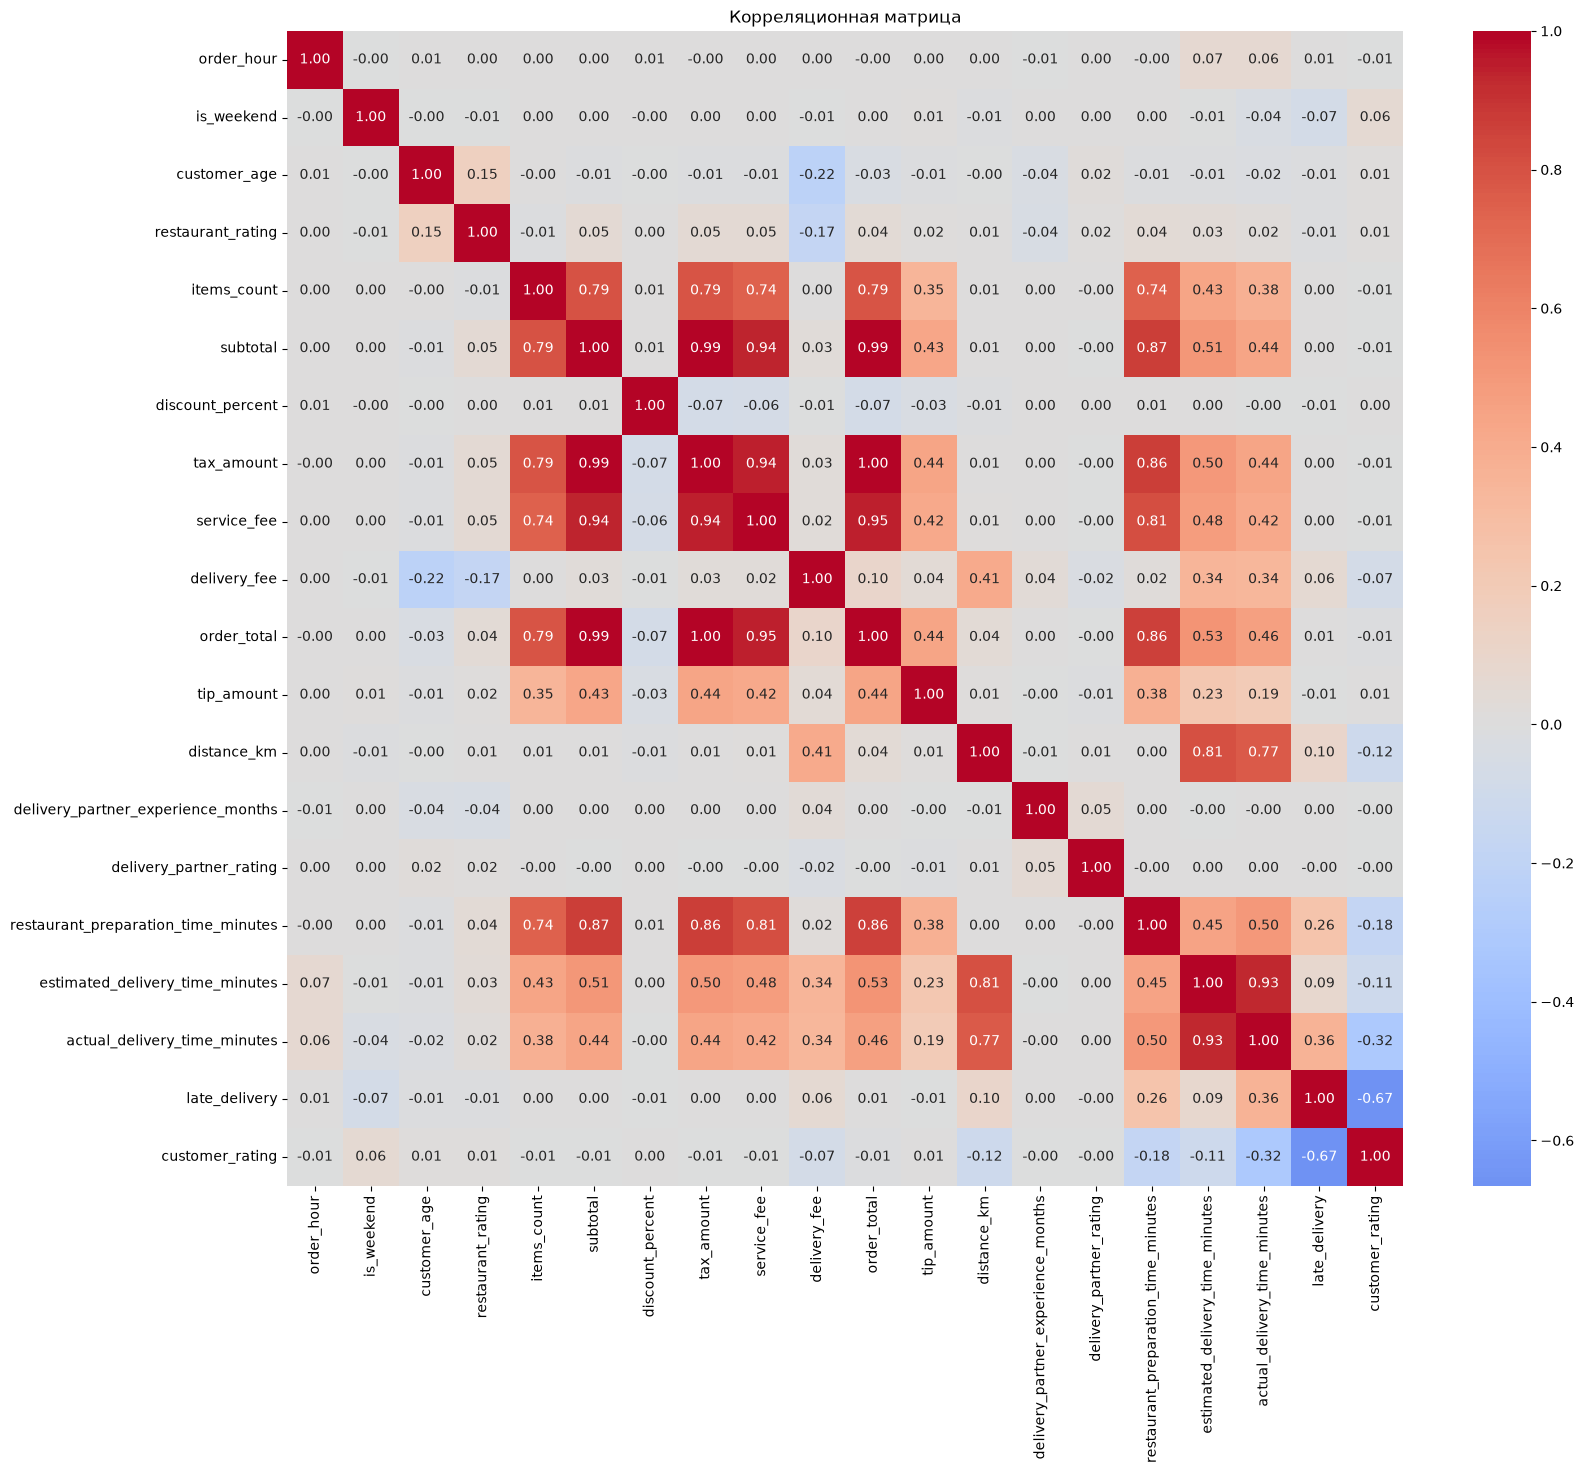

In [28]:
plt.figure(figsize=(18, 15))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Корреляционная матрица')
plt.show()

На целевой признак **late_delivery** влияют признаки **restaurant_preparation_time_minutes** и **distance_km** что подтверждает выводы по предыдущим графикам. Также есть влиянием от **estimated_delivery_time_minutes**. Основная зависимость от **restaurant_preparation_time_minutes**  

Зависимости других признаков:
У **restaurant_preparation_time_minutes** высокая зависимость от **order_total**. Так как у **late_delivery** сильная зависимость от **restaurant_preparation_time_minutes**, оставим его  
У **distance_km** высокая зависимость от **estimated_delivery_time_minutes**. Видимо ожидаемое время доставки считается от дистанции. Оставим дистанцию   

Финансовый блок:  
У **order_total** высокая зависимость от **subtotal**, **tax_amount**, **service_fee**, потому что **order_total** это сумма этих показателей  
Также у **order_total** зависимость ближе к высокой от **items_count**   

В финансовом блоке сильная зависимость между признаками, но **целевой признак очень слабо зависит от финансовых показателей**. От финансовых показателей зависит **restaurant_preparation_time_minutes**, от которого есть зависимость от целевого показателя  



In [29]:
df_drop_columns.drop(["tax_amount", "service_fee", "subtotal", "estimated_delivery_time_minutes", "order_total", "items_count"], axis=1, inplace=True)

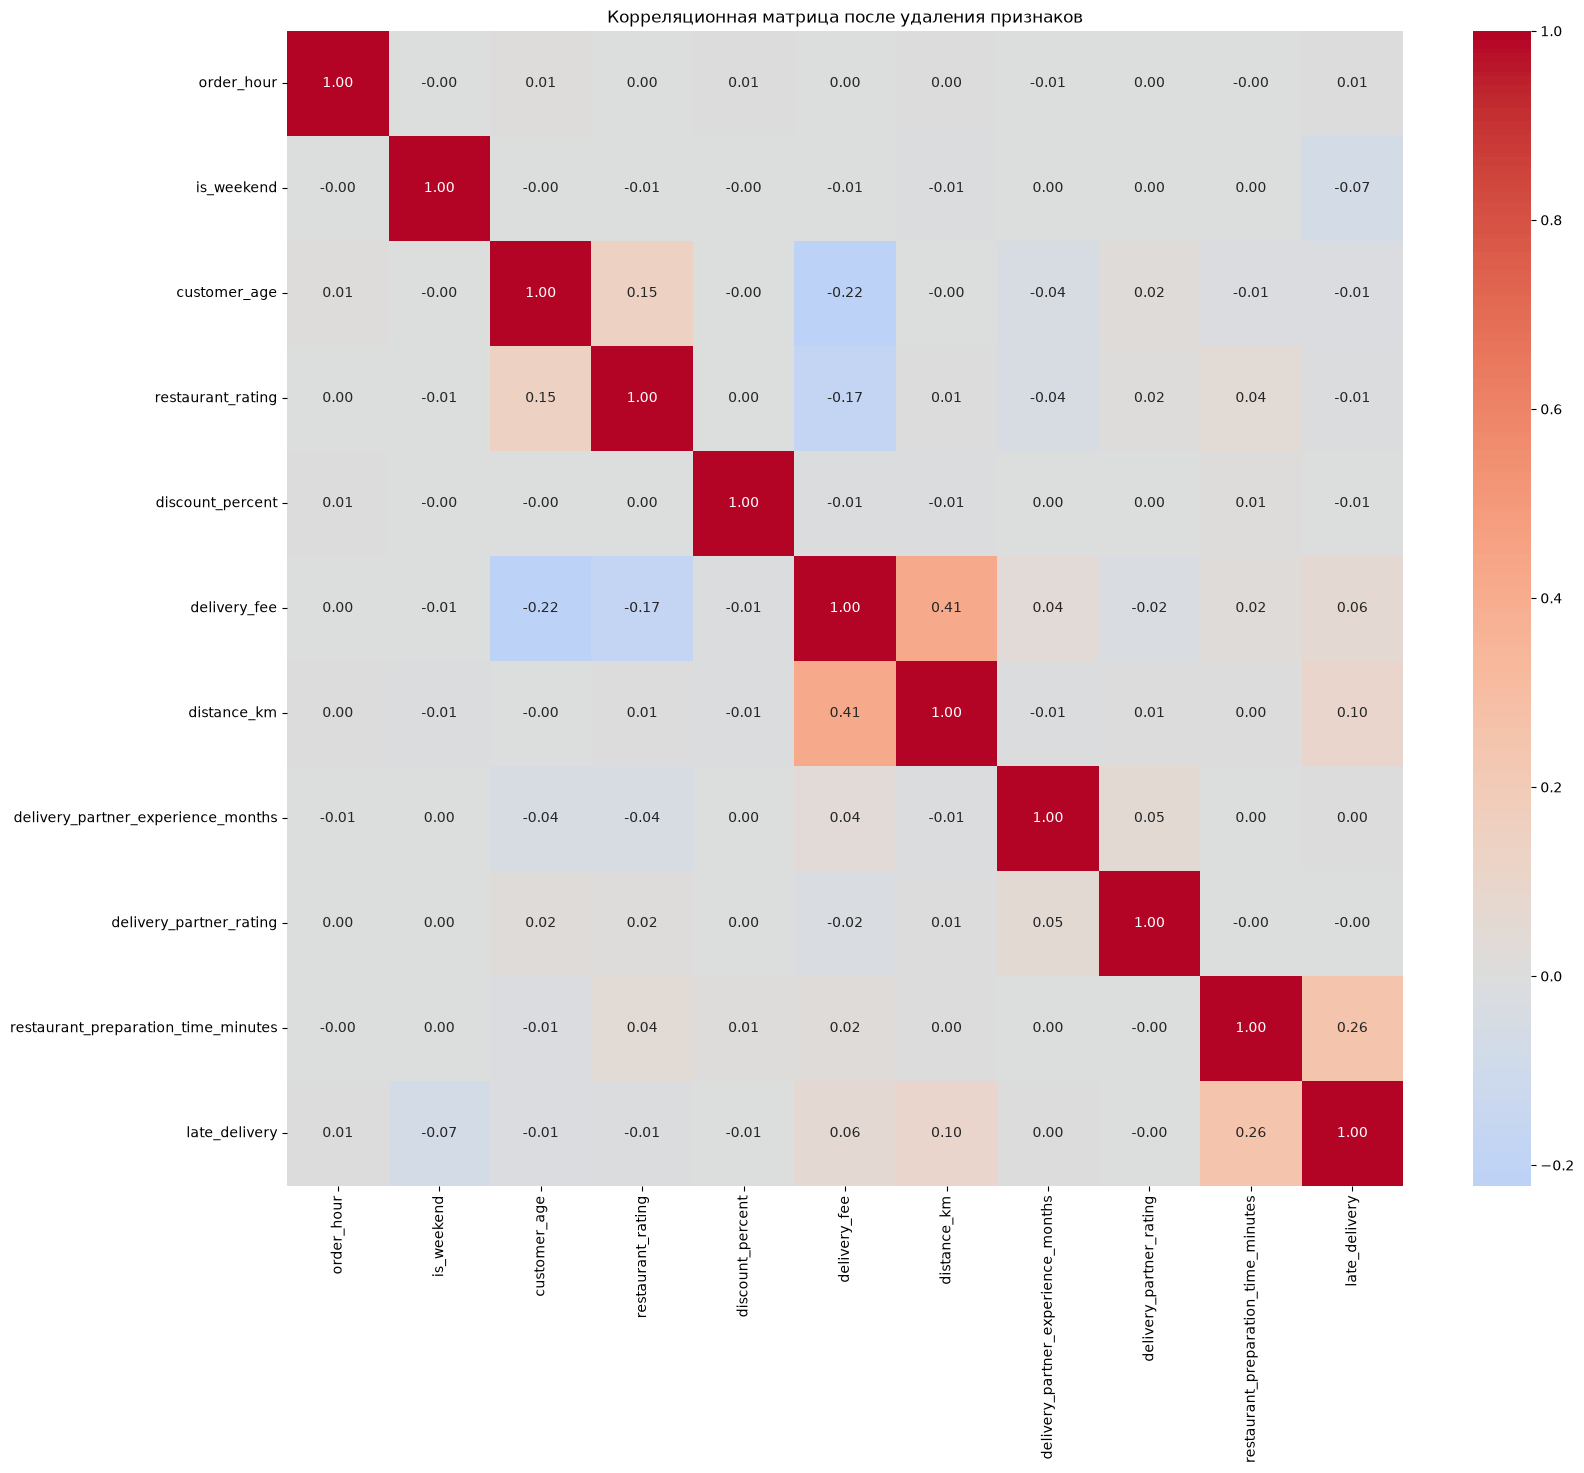

In [30]:
plt.figure(figsize=(18, 15))

sns.heatmap(
    df_drop_columns.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Корреляционная матрица после удаления признаков')
plt.show()

In [31]:
df.drop(["tax_amount", "service_fee", "subtotal", "estimated_delivery_time_minutes", "order_total", "items_count"], axis=1, inplace=True)
df.drop([
    "order_id",
    "customer_id",
    "restaurant_id",
    "driver_id",
    "actual_delivery_time_minutes",
    "customer_rating",
    "tip_amount",
    "cancellation_reason",
    "order_status",
    "city",
    "order_timestamp"
], axis=1, inplace=True)

## **Промежуточный итог**

Стоит обратить внимание на признаки:  
Высокое влияние  
- **distance_km**  
- **restaurant_preparation_time_minutes**  
- **weather**  

Среднее влияние  
- **delivery_area** 
- **day_of_week**  

## **Подготовка данных для линейной регрессии**

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

df["order_date"] = pd.to_datetime(df["order_date"])

train_df = df[(df["order_date"] >= "2025-10-01") & (df["order_date"] < "2025-10-17")].copy()
validation_df = df[(df["order_date"] >= "2025-10-17") & (df["order_date"] < "2025-10-24")].copy()
test_df = df[(df["order_date"] >= "2025-10-24") & (df["order_date"] < "2025-10-31")].copy()

X_train = train_df.drop(columns=["late_delivery", "order_date"])
y_train = train_df["late_delivery"]

X_validation = validation_df.drop(columns=["late_delivery", "order_date"])
y_validation = validation_df["late_delivery"]

X_test = test_df.drop(columns=["late_delivery", "order_date"])
y_test = test_df["late_delivery"]

categorical_features = X_train.select_dtypes(include=["object", "str"]).columns.tolist()
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=100
    ))
])

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features),
        ('num', numeric_transformer, numeric_features)
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_validation)
X_test_prepared = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

df_train = pd.DataFrame(
    X_train_prepared.toarray() if hasattr(X_train_prepared, "toarray")
    else X_train_prepared,
    columns=feature_names
)

df_val = pd.DataFrame(
    X_val_prepared.toarray() if hasattr(X_val_prepared, "toarray")
    else X_val_prepared,
    columns=feature_names
)

df_test = pd.DataFrame(
    X_test_prepared.toarray() if hasattr(X_test_prepared, "toarray")
    else X_test_prepared,
    columns=feature_names
)

df_train["late_delivery"] = y_train.values
df_val["late_delivery"] = y_validation.values
df_test["late_delivery"] = y_test.values

df_train.to_csv("dataframes/logistic_regression_train.csv", index=False)
df_val.to_csv("dataframes/logistic_regression_validation.csv", index=False)
df_test.to_csv("dataframes/logistic_regression_test.csv", index=False)

## **Подготовка данных для CatBoost**

In [33]:
df.drop(["order_date"], axis=1, inplace=True)

In [34]:
df.to_csv(
    'dataframes/cat_boost.csv',
    index=False
)